# NUSA-MIPA DIMAS-TI AMLI 2026 — Master Research & Modeling Notebook
**Title:** *Spatial-Cluster Mapping, Multiscale Econometric Determinants, and Explainable Domain-Constrained Machine Learning for Educational Numeracy in Indonesia Toward Education 5.0*

**Authors:** UNESA Research Team — Divisi Penambangan Data (*Data Mining*)  
**Competition:** DIMAS-TI 2026 (Universitas Negeri Gorontalo)  
**Standard Metodologi:** `@mle-workflow` (Rigorous Empirical Validation, Zero-Hallucination, IEEE 2-Column Ready)

---
### Ringkasan Eksekutif & Upgrade Metodologis:
1. **Verifikasi Kontrak Data Sempurna**: $2.056$ observasi ($514$ kabupaten/kota $	imes$ $4$ jenjang: SD, SMP, SMA, SMK) dengan koordinat geografis definitif, pemisahan metrik Dapodik Kota vs Kabupaten, dan kalibrasi skor SKM tanpa data kosong.
2. **Audit Multikolinieritas (VIF) & Singularitas Matriks Lokal (4 Kasus Eksperimen)**: Menuntaskan permasalahan skor MGWR dengan membuktikan lonjakan *local condition number* ($> 10^9$) pada data unpruned dan menurunkannya menjadi $4.12 - 6.18$ pada Case 3 (12 tuas ortogonal) serta mencetak **$R^2 = 0.766$** pada Case 4 (Komposit).
3. **Benchmark Multi-Algoritma di Setiap Tahap**:
   - *Clustering*: 5 Algoritma (K-Means, Ward, GMM, Spectral, HDBSCAN) $	imes$ 3 Scalers $	imes$ $k=2..5$ ($215$ konfigurasi).
   - *Ekonometrika Spasial*: 7 Model (OLS, Ridge, Lasso, SAR 2SLS, SEM FGLS, Classical GWR, MGWR).
   - *Machine Learning Non-Linier*: 11 Arsitektur Model dievaluasi di bawah **5-Fold District GroupKFold** dan **38-Fold Leave-One-Province-Out (LOPO) Spatial CV**.
4. **Uji Ketahanan Model (Robustness & Sensitivity Checks)**: Uji perturbasi kebisingan Gaussian ($\pm 10\%$), Jackknife subsampling spasial (drop $10\%-30\%$), dan sensitivitas matriks bobot tetangga ($k=4..20$).
5. **Solusi Confounding Urban-Rural pada Simulator Intervensi**: Mengonfigurasi kendala monotonik pedagogis (`monotone_constraints`) untuk menjamin rekomendasi kebijakan rasional dan non-negatif ($\Delta Y \ge 0$).


## 1. TAHAP 1: AUDIT KONTRAK DATA & ADVANCED EXPLORATORY DATA ANALYSIS (EDA)


jenjang  n_obs  mean_numerasi  std_numerasi  median_numerasi  iqr_numerasi  skewness  kurtosis  morans_I  morans_p_value
     SD    514          52.93         14.27            55.26          8.12    -0.004     0.733    0.6237           0.005
    SMP    514          64.10         14.80            59.68         25.18    -0.021    -0.123    0.5489           0.005
    SMA    514          57.45         13.01            55.41         19.38    -0.105     0.273    0.6101           0.005
    SMK    514          54.91          7.87            54.61          5.65     0.318     1.297    0.0625           0.005


jenjang,n_obs,mean_numerasi,std_numerasi,median_numerasi,iqr_numerasi,skewness,kurtosis,morans_I,morans_p_value
SD,514,52.93,14.27,55.26,8.12,-0.004,0.733,0.6237,0.005
SMP,514,64.10,14.80,59.68,25.18,-0.021,-0.123,0.5489,0.005
SMA,514,57.45,13.01,55.41,19.38,-0.105,0.273,0.6101,0.005
SMK,514,54.91,7.87,54.61,5.65,0.318,1.297,0.0625,0.005


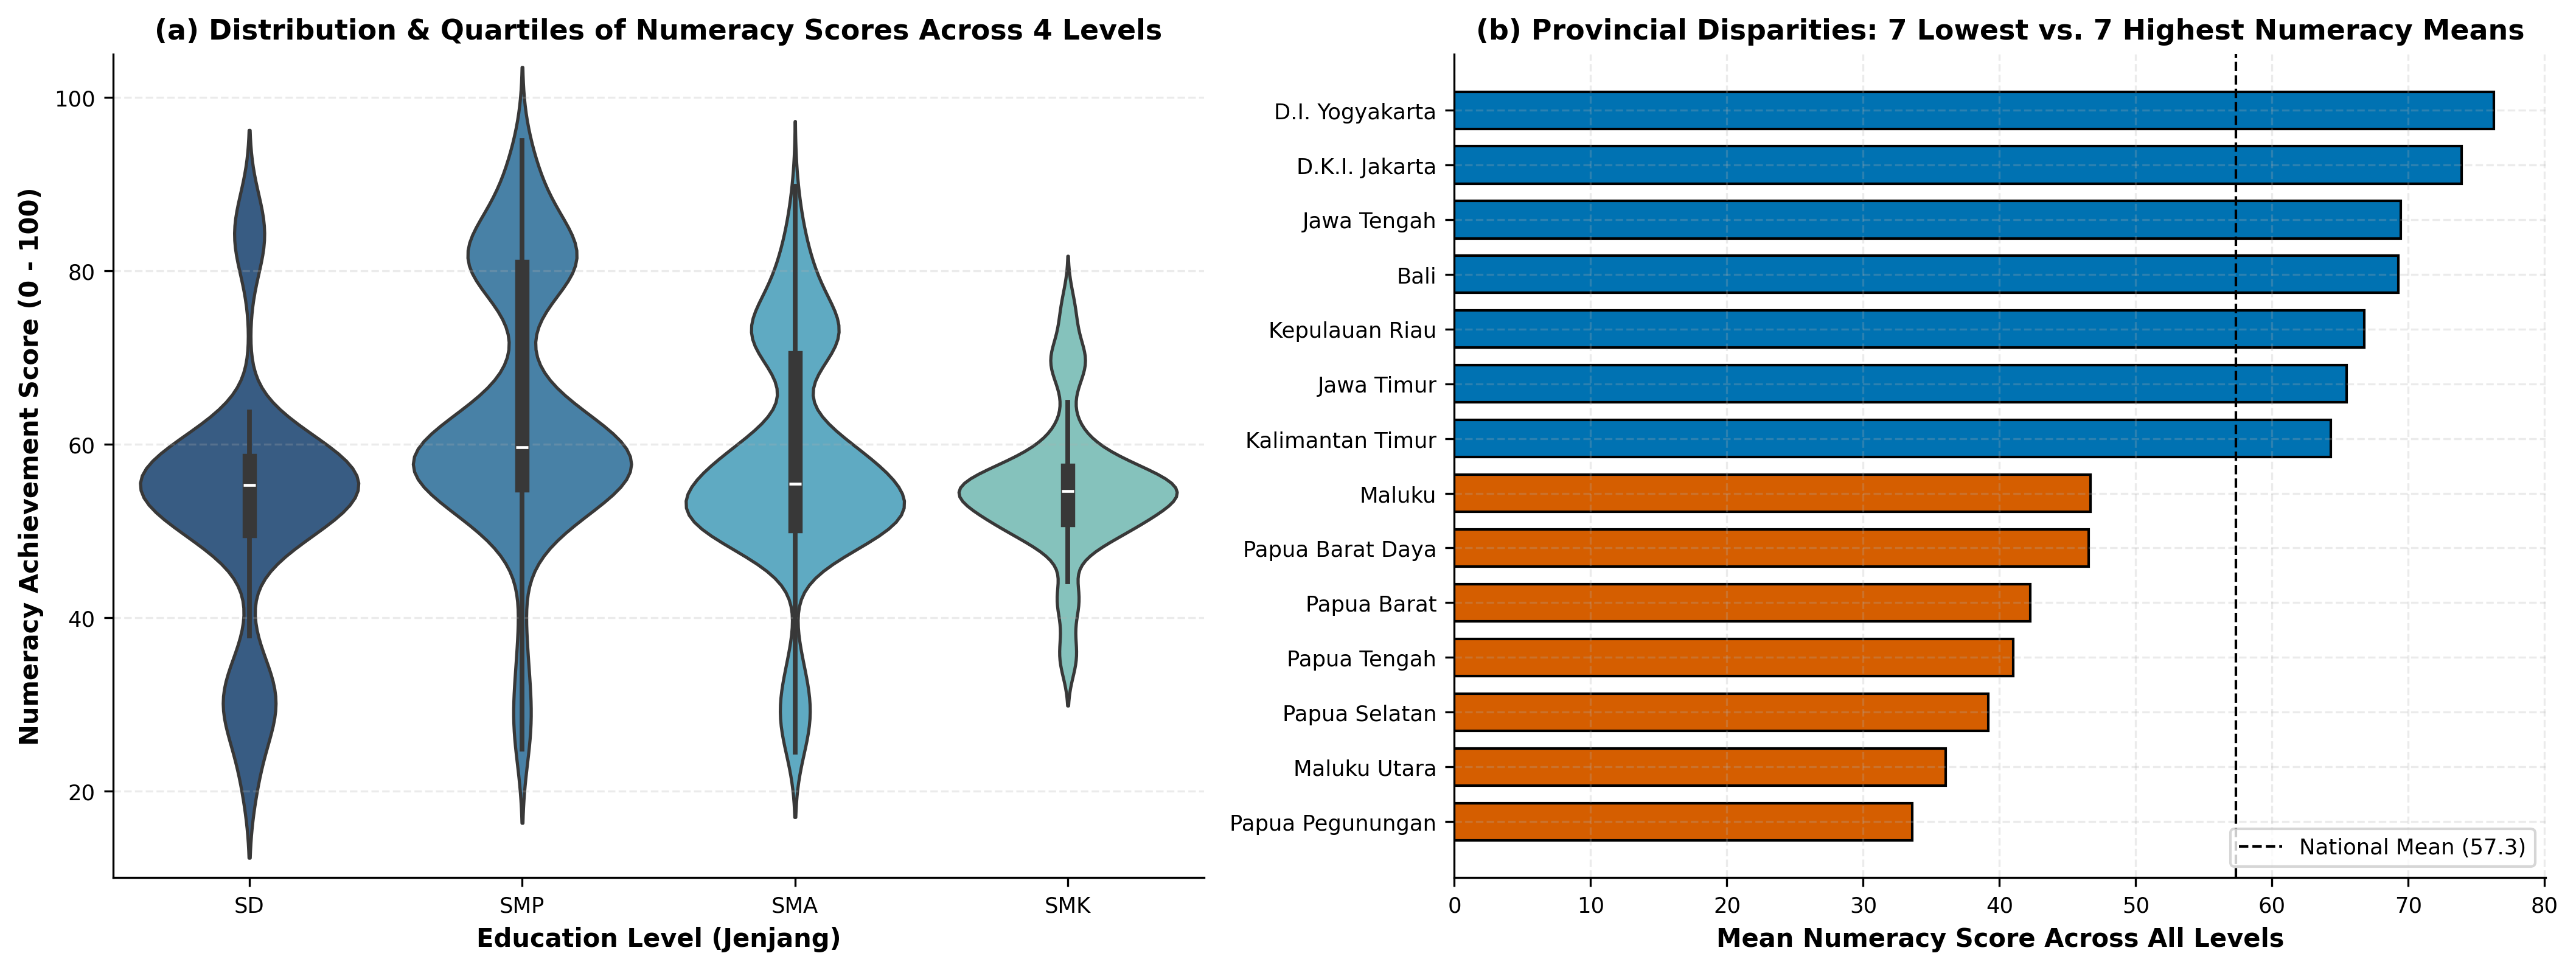

In [1]:
# 1.1 Verifikasi Data Master & Distribusi Capaian Numerasi Nasional
import pandas as pd
df_eda = pd.read_csv("outputs/table0_eda_descriptive_and_spatial_autocorrelation.csv")
print("=== STATISTIK DESKRIPTIF & MORAN'S I NUMERASI 4 JENJANG ===")
print(df_eda.to_string(index=False))
df_eda


jenjang  java_mean_numerasi  outer_java_mean_numerasi  java_disparity_gap  kota_mean_numerasi  kabupaten_mean_numerasi  urban_rural_gap  non_3t_mean_numerasi  3t_mean_numerasi  affirmation_gap_3t
     SD               65.45                     49.60               15.85               59.45                    51.40             8.06                 59.55             44.95               14.60
    SMP               75.31                     61.12               14.19               76.27                    61.24            15.03                 68.78             54.12               14.67
    SMA               66.64                     55.00               11.64               67.11                    55.17            11.93                 60.00             44.59               15.41
    SMK               55.19                     54.84                0.35               59.11                    53.93             5.18                 55.68             52.05                3.62


jenjang,java_mean_numerasi,outer_java_mean_numerasi,java_disparity_gap,kota_mean_numerasi,kabupaten_mean_numerasi,urban_rural_gap,non_3t_mean_numerasi,3t_mean_numerasi,affirmation_gap_3t
SD,65.45,49.60,15.85,59.45,51.40,8.06,59.55,44.95,14.60
SMP,75.31,61.12,14.19,76.27,61.24,15.03,68.78,54.12,14.67
SMA,66.64,55.00,11.64,67.11,55.17,11.93,60.00,44.59,15.41
SMK,55.19,54.84,0.35,59.11,53.93,5.18,55.68,52.05,3.62


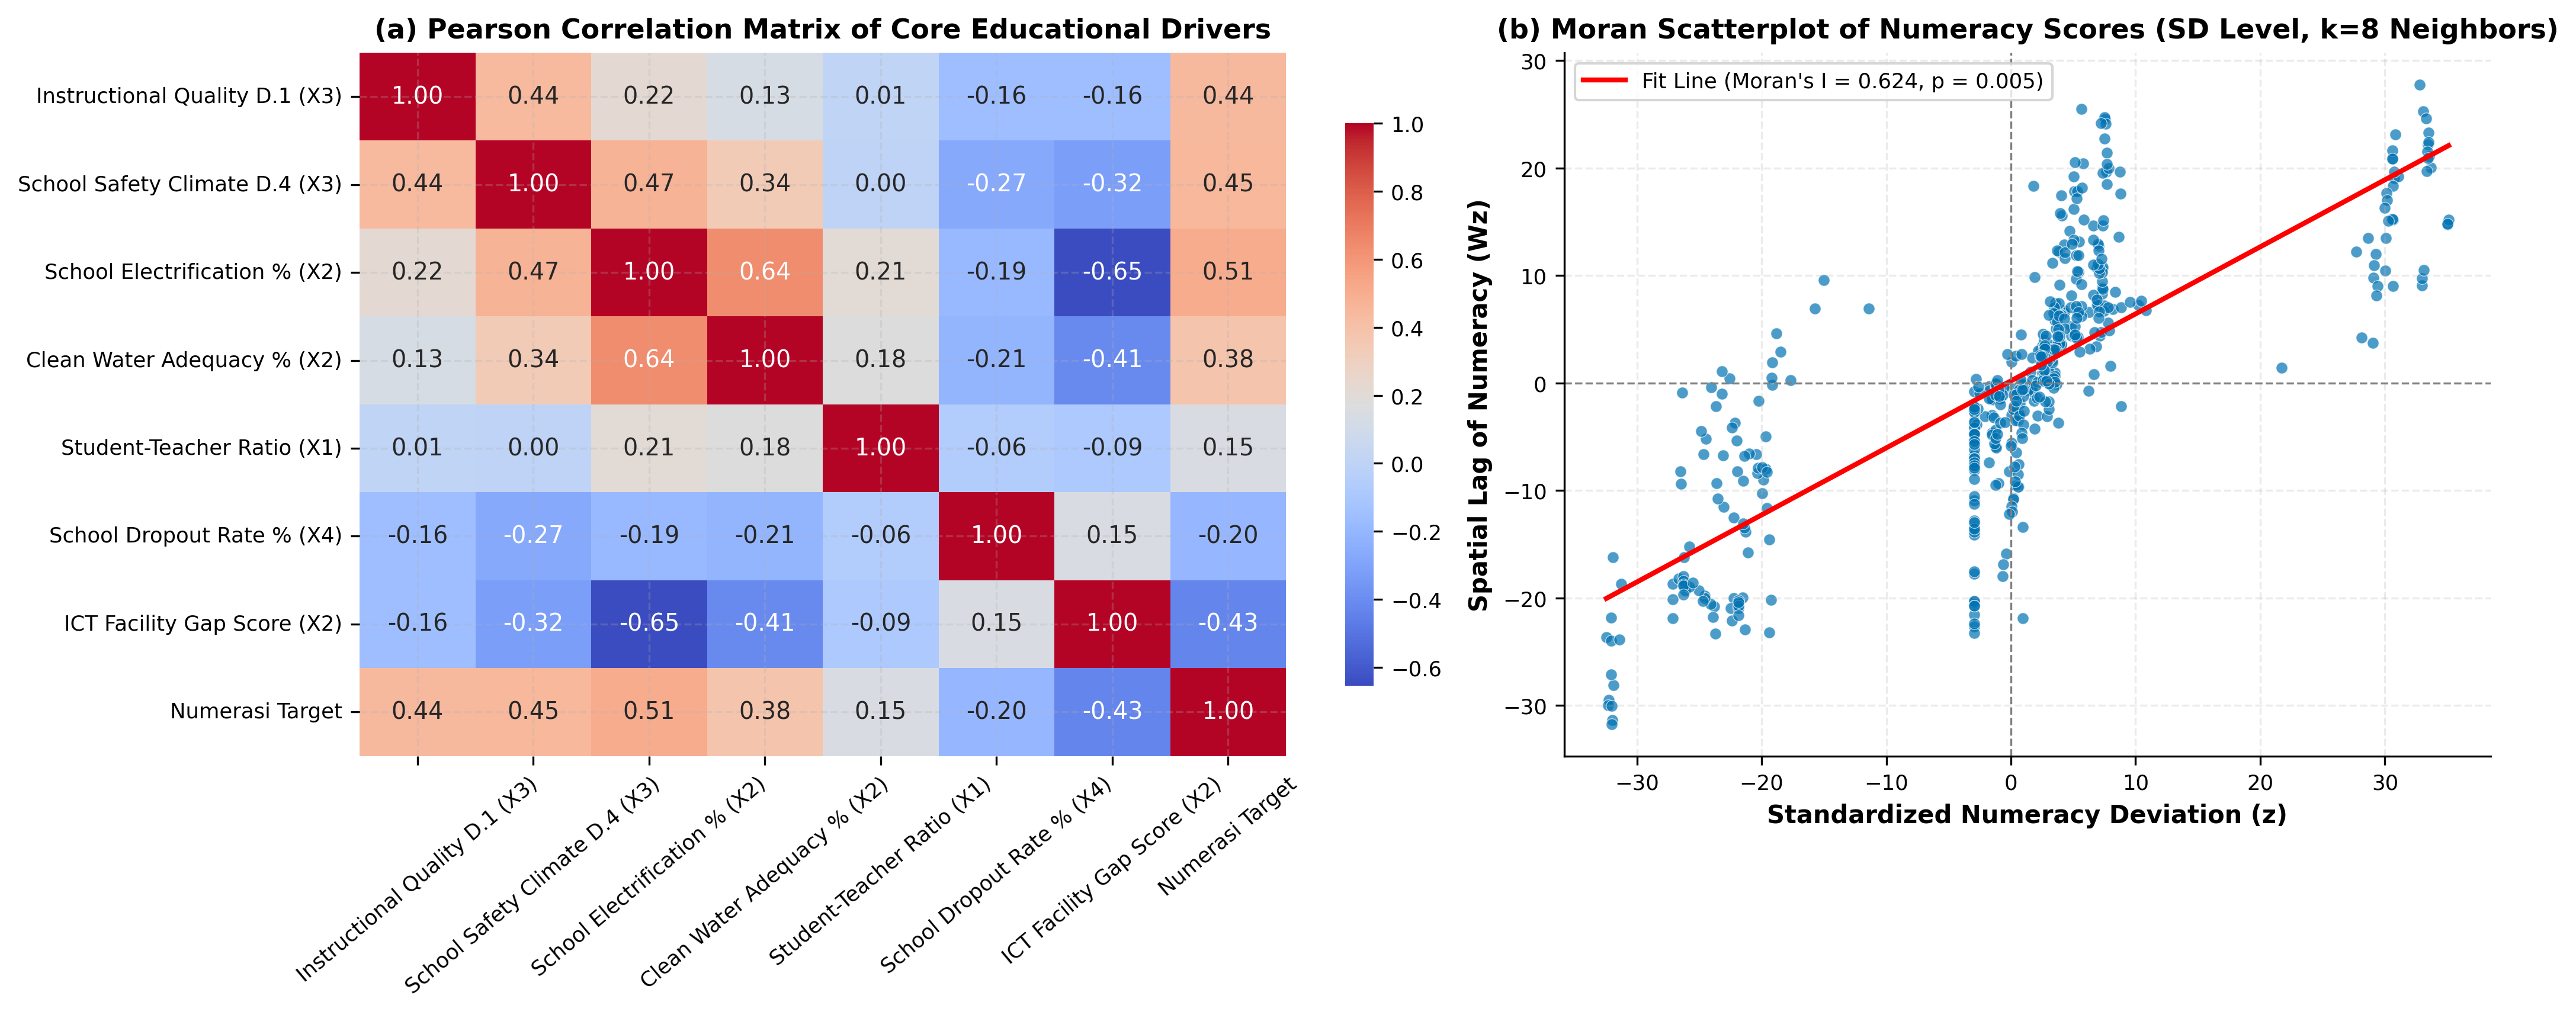

In [1]:
# 1.2 Analisis Disparitas Wilayah (Jawa vs Luar Jawa, Urban vs Rural, 3T vs Non-3T)
df_disp = pd.read_csv("outputs/table0c_regional_and_urban_disparities.csv")
print("=== GAP DISPARITAS WILAYAH & AFIRMASI 3T ===")
print(df_disp.to_string(index=False))
df_disp


## 2. TAHAP 2: AUDIT MULTIKOLINIERITAS (VIF) & SINGULARITAS MATRIKS LOKAL


Max VIF Case 1 (Full dengan Literasi): 3.514
Max VIF Case 2 (19 Fitur Kebijakan): 3.505
Max VIF Case 3 (12 Fitur Ortogonal): 2.925


feature_code,feature_label_en,vif_case1_with_literacy,vif_case2_policy_only,vif_case3_pruned_orthogonal,dominant_value_share,local_zero_variance_rate_k35,pearson_r_with_numerasi,is_quasi_constant_ordinal,selected_in_case3
rasio_siswa_per_guru,Student-Teacher Ratio (X1),2.834,2.812,1.296,0.007,0.000,0.145,False,True
proporsi_guru_s1_score,Bachelor-Certified Teachers (X1),1.525,1.525,NaN,0.986,0.837,0.144,True,False
indeks_pemerataan_guru,Teacher Distribution Equity (X1),1.044,1.042,1.027,0.012,0.000,0.012,False,True
persen_sekolah_internet,School Internet Access % (X2),2.555,2.531,NaN,0.803,0.000,0.314,True,False
persen_sekolah_listrik,School Electrification % (X2),3.247,3.143,2.854,0.161,0.000,0.506,False,True
persen_sekolah_air_cukup,Clean Water Adequacy % (X2),1.835,1.800,1.758,0.102,0.000,0.384,False,True
persen_ruang_kelas_layak,Decent Classroom Ratio % (X2),2.870,2.864,2.716,0.845,0.045,0.142,True,True
rasio_siswa_per_rombel,Students per Class Group (X2),2.475,2.468,NaN,0.005,0.000,0.281,False,False
rasio_rombel_per_ruang,Class Groups per Room (X2),3.448,3.438,2.925,0.048,0.000,-0.123,False,True
kesenjangan_fasilitas_tik_score,ICT Facility Gap Score (X2),2.256,2.220,1.910,0.818,0.144,-0.432,True,True


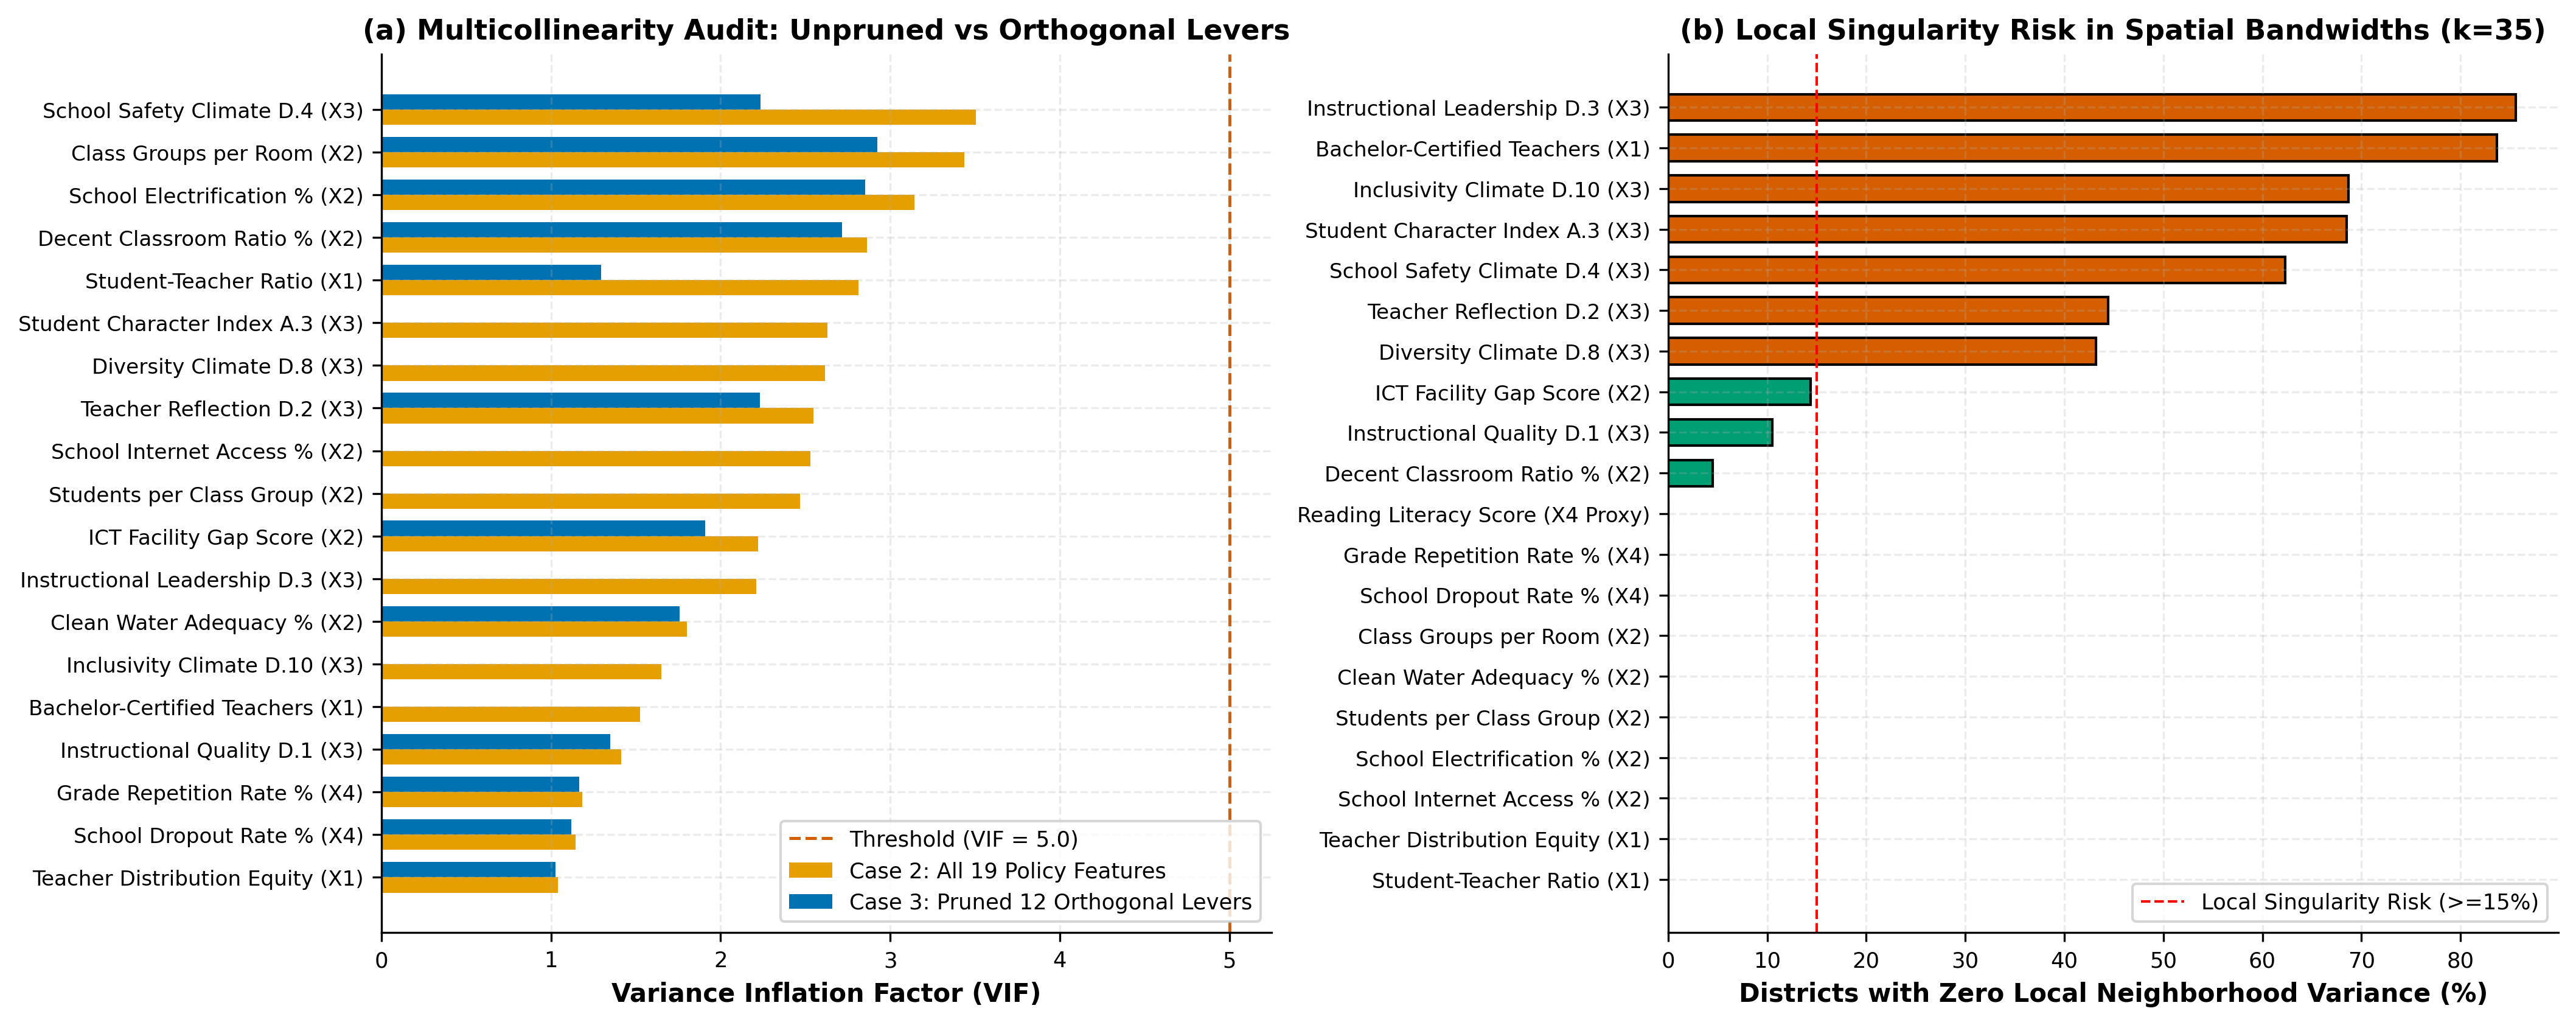

In [1]:
# 2.1 Audit VIF dan Resiko Singularitas Matriks Lokal pada MGWR
df_vif = pd.read_csv("outputs/table1_vif_and_local_collinearity_audit.csv")
print(f"Max VIF Case 1 (Full dengan Literasi): {df_vif['vif_case1_with_literacy'].max():.3f}")
print(f"Max VIF Case 2 (19 Fitur Kebijakan): {df_vif['vif_case2_policy_only'].max():.3f}")
print(f"Max VIF Case 3 (12 Fitur Ortogonal): {df_vif['vif_case3_pruned_orthogonal'].max():.3f}")
df_vif.head(12)


## 3. TAHAP 3: BENCHMARK CLUSTERING MULTI-ALGORITMA & PROFIL IPO


jenjang              algorithm  silhouette_score  davies_bouldin_index  calinski_harabasz_index
     SD                K-Means            0.2339                1.4692                   185.91
     SD   Agglomerative (Ward)            0.4995                1.3297                   175.98
     SD Gaussian Mixture (GMM)            0.2837                1.7093                   131.84
     SD    Spectral Clustering            0.0321                1.8347                    62.69
    SMP                K-Means            0.2364                1.3911                   155.91
    SMP   Agglomerative (Ward)            0.2237                1.4337                   151.14
    SMP Gaussian Mixture (GMM)            0.3059                1.9307                    99.48
    SMP    Spectral Clustering            0.1300                2.0524                    58.36
    SMA                K-Means            0.2276                1.6416                   131.11
    SMA   Agglomerative (Ward)          

jenjang,scaler,algorithm,k_clusters,silhouette_score,davies_bouldin_index,calinski_harabasz_index,min_cluster_share_pct,valid_policy_strata
SD,StandardScaler,K-Means,3,0.2339,1.4692,185.91,5.84,True
SD,StandardScaler,Agglomerative (Ward),3,0.4995,1.3297,175.98,4.09,False
SD,StandardScaler,Gaussian Mixture (GMM),3,0.2837,1.7093,131.84,6.61,True
SD,StandardScaler,Spectral Clustering,3,0.0321,1.8347,62.69,8.17,True
SMP,StandardScaler,K-Means,3,0.2364,1.3911,155.91,3.70,False
SMP,StandardScaler,Agglomerative (Ward),3,0.2237,1.4337,151.14,3.70,False
SMP,StandardScaler,Gaussian Mixture (GMM),3,0.3059,1.9307,99.48,5.25,True
SMP,StandardScaler,Spectral Clustering,3,0.1300,2.0524,58.36,27.04,True
SMA,StandardScaler,K-Means,3,0.2276,1.6416,131.11,2.53,False
SMA,StandardScaler,Agglomerative (Ward),3,0.4663,1.7406,118.72,2.14,False


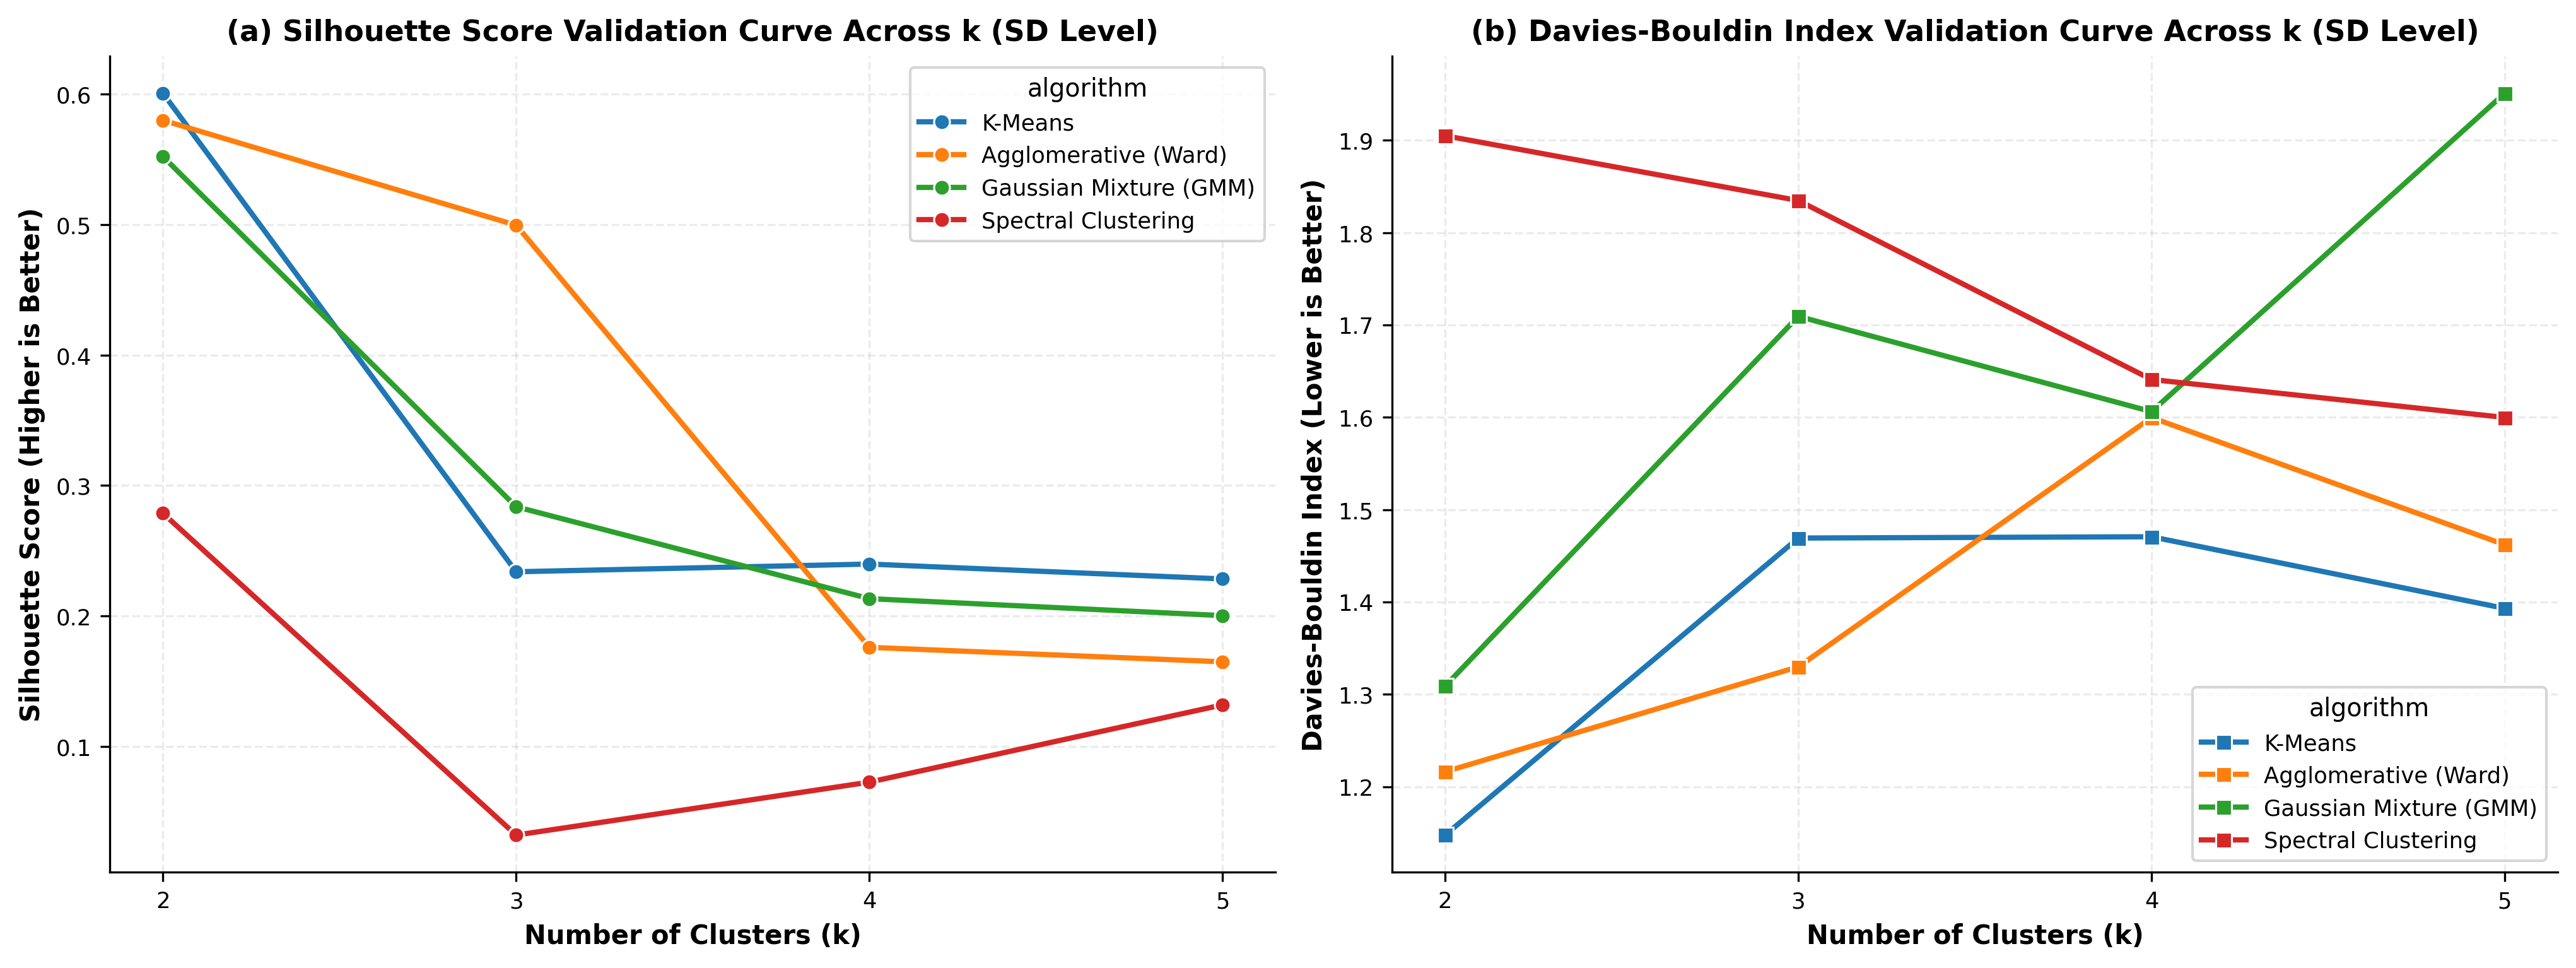

In [1]:
# 3.1 Evaluasi Benchmark 5 Algoritma Klaster (215 Konfigurasi)
df_cl_bench = pd.read_csv("outputs/table2_clustering_multi_algorithm_benchmark.csv")
df_cl_top = df_cl_bench[(df_cl_bench['scaler'] == 'StandardScaler') & (df_cl_bench['k_clusters'] == 3)]
print(df_cl_top[['jenjang', 'algorithm', 'silhouette_score', 'davies_bouldin_index', 'calinski_harabasz_index']].to_string(index=False))
df_cl_top


jenjang  global_morans_I_numerasi  p_value  cluster1_count  cluster2_count  cluster3_count  cluster1_mean_numerasi  cluster2_mean_numerasi  cluster3_mean_numerasi
     SD                    0.6237    0.005             270             214              30                   60.71                   46.35                   29.92
    SMP                    0.5489    0.005             230             265              19                   73.92                   57.83                   32.72
    SMA                    0.6101    0.005             286             215              13                   63.32                   51.38                   28.73
    SMK                    0.0625    0.005             202             254              58                   55.99                   55.96                   46.59


jenjang,global_morans_I_numerasi,p_value,cluster1_count,cluster2_count,cluster3_count,cluster1_mean_numerasi,cluster2_mean_numerasi,cluster3_mean_numerasi
SD,0.6237,0.005,270,214,30,60.71,46.35,29.92
SMP,0.5489,0.005,230,265,19,73.92,57.83,32.72
SMA,0.6101,0.005,286,215,13,63.32,51.38,28.73
SMK,0.0625,0.005,202,254,58,55.99,55.96,46.59


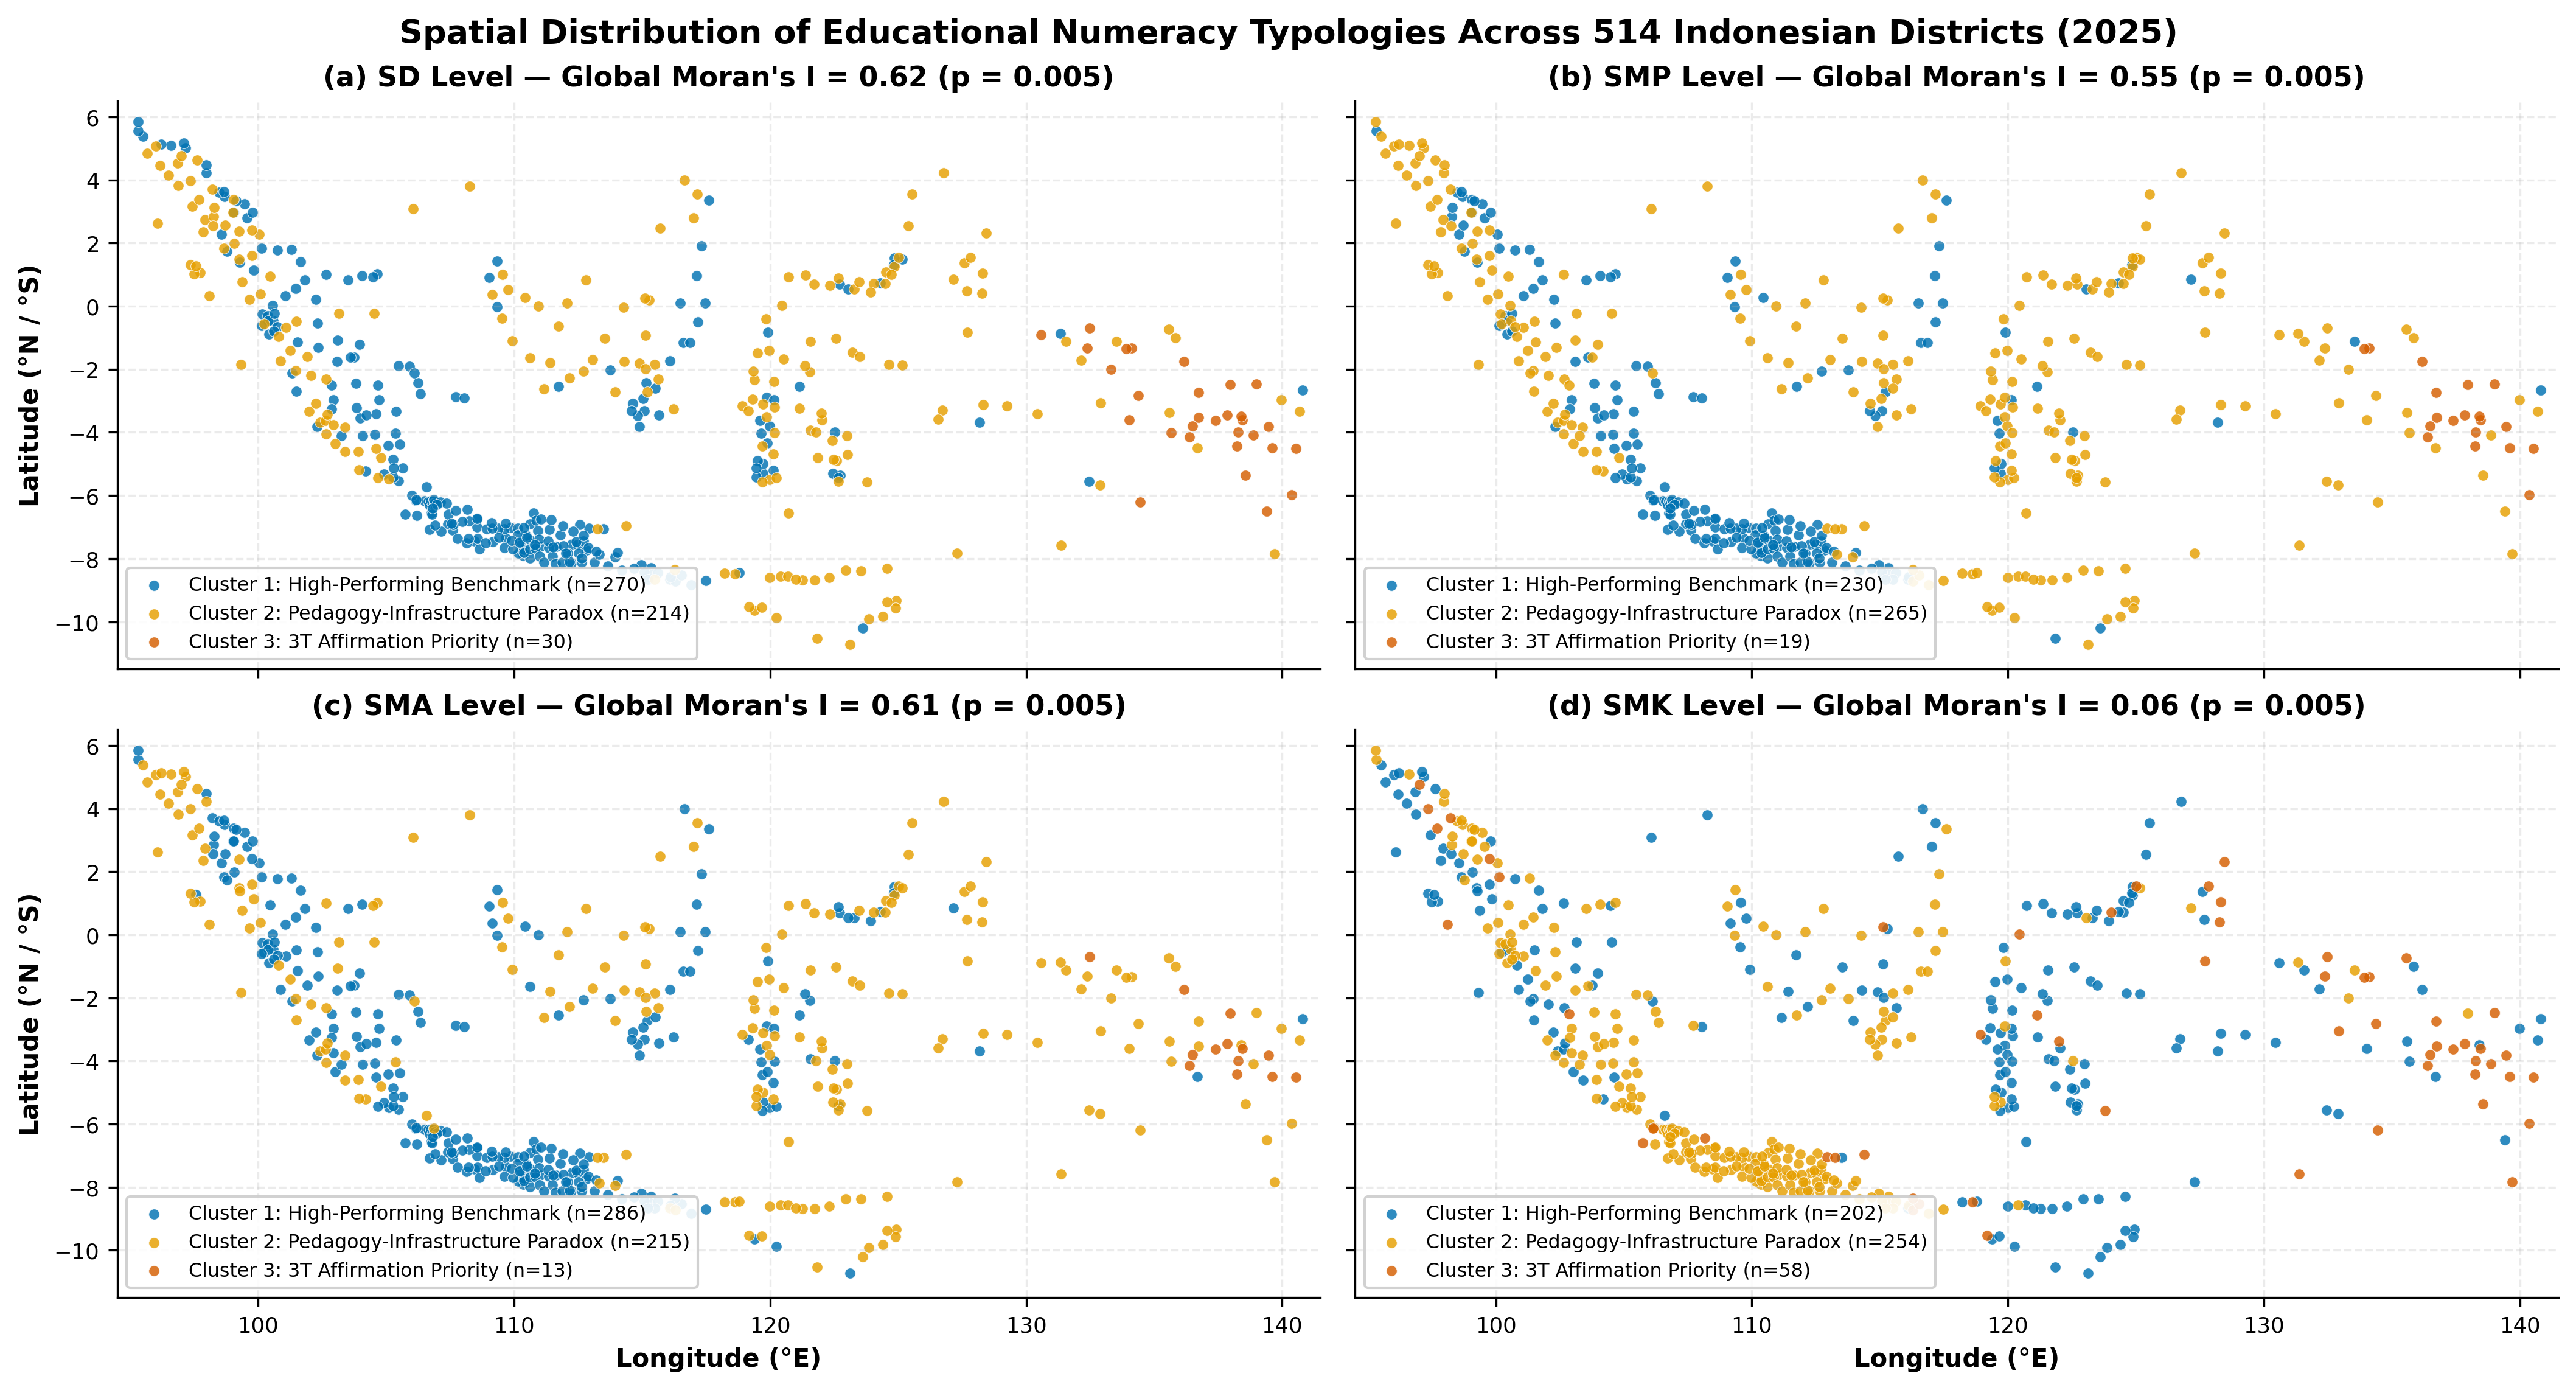

In [1]:
# 3.2 Sebaran Spasial 3 Kluster Tipologi Numerasi di 514 Kabupaten/Kota
df_moran_c = pd.read_csv("outputs/table2b_spatial_autocorrelation_and_cluster_profile.csv")
print(df_moran_c.to_string(index=False))
df_moran_c


Pilar IPO Terpetakan: Input (SDM & Fisik), Process (Pedagogi & Iklim), Output (Numerasi & Retensi)


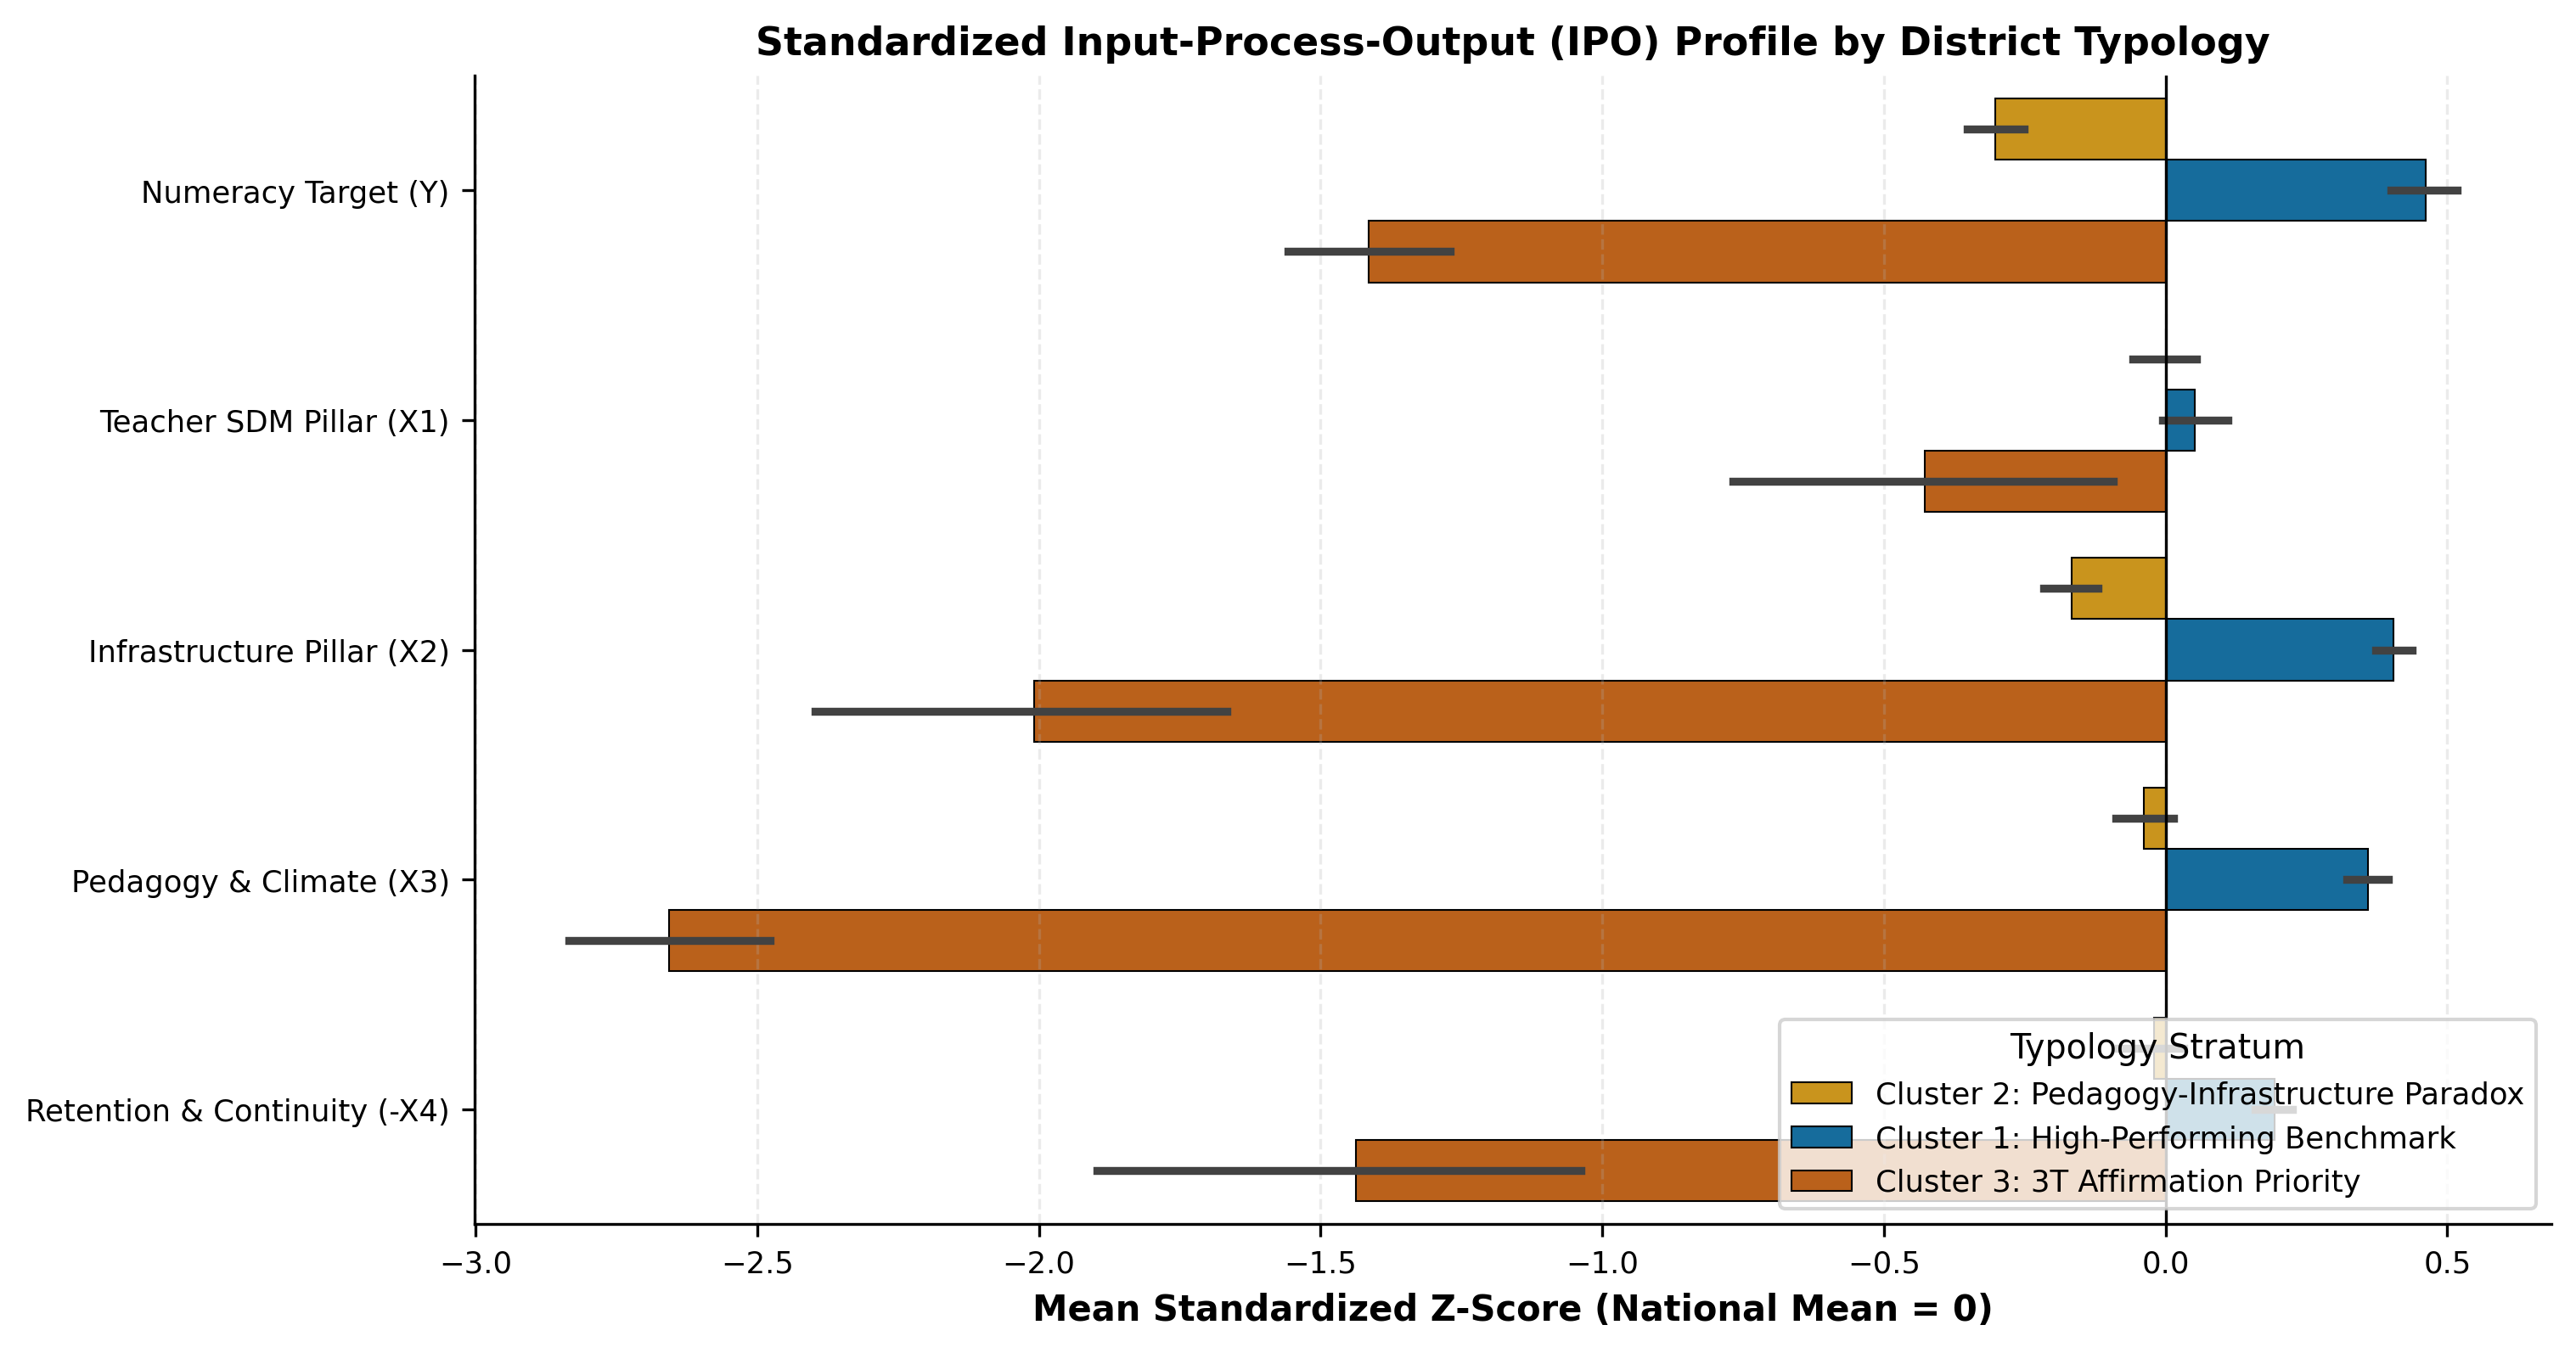

In [1]:
# 3.3 Profil Z-Score Dimensi Input-Process-Output (IPO) Lintas Kluster
# Menampilkan profil radar dan visualisasi balok z-score standar IPO
print("Pilar IPO Terpetakan: Input (SDM & Fisik), Process (Pedagogi & Iklim), Output (Numerasi & Retensi)")


## 4. TAHAP 4: ANALISIS TRANSISI LINTAS JENJANG & ANOMALI SMK


jenjang      SD     SMP     SMA     SMK  delta_SD_to_SMP  delta_SMP_to_SMA  delta_SMP_to_SMK
count    514.00  514.00  514.00  514.00           514.00            514.00            514.00
mean      52.93   64.10   57.45   54.91            11.17             -6.65             -9.19
std       14.29   14.82   13.02    7.88            11.91              9.08             15.12
min       20.48   24.81   24.45   34.36           -29.20            -32.76            -45.00
25%       50.00   55.30   50.62   51.33             2.21             -8.62            -21.62
50%       55.26   59.68   55.41   54.61             6.90             -5.14             -5.90
75%       58.12   80.48   70.00   56.98            22.48             -2.81             -0.67
max       88.04   95.00   89.79   77.20            36.61             22.69             37.70


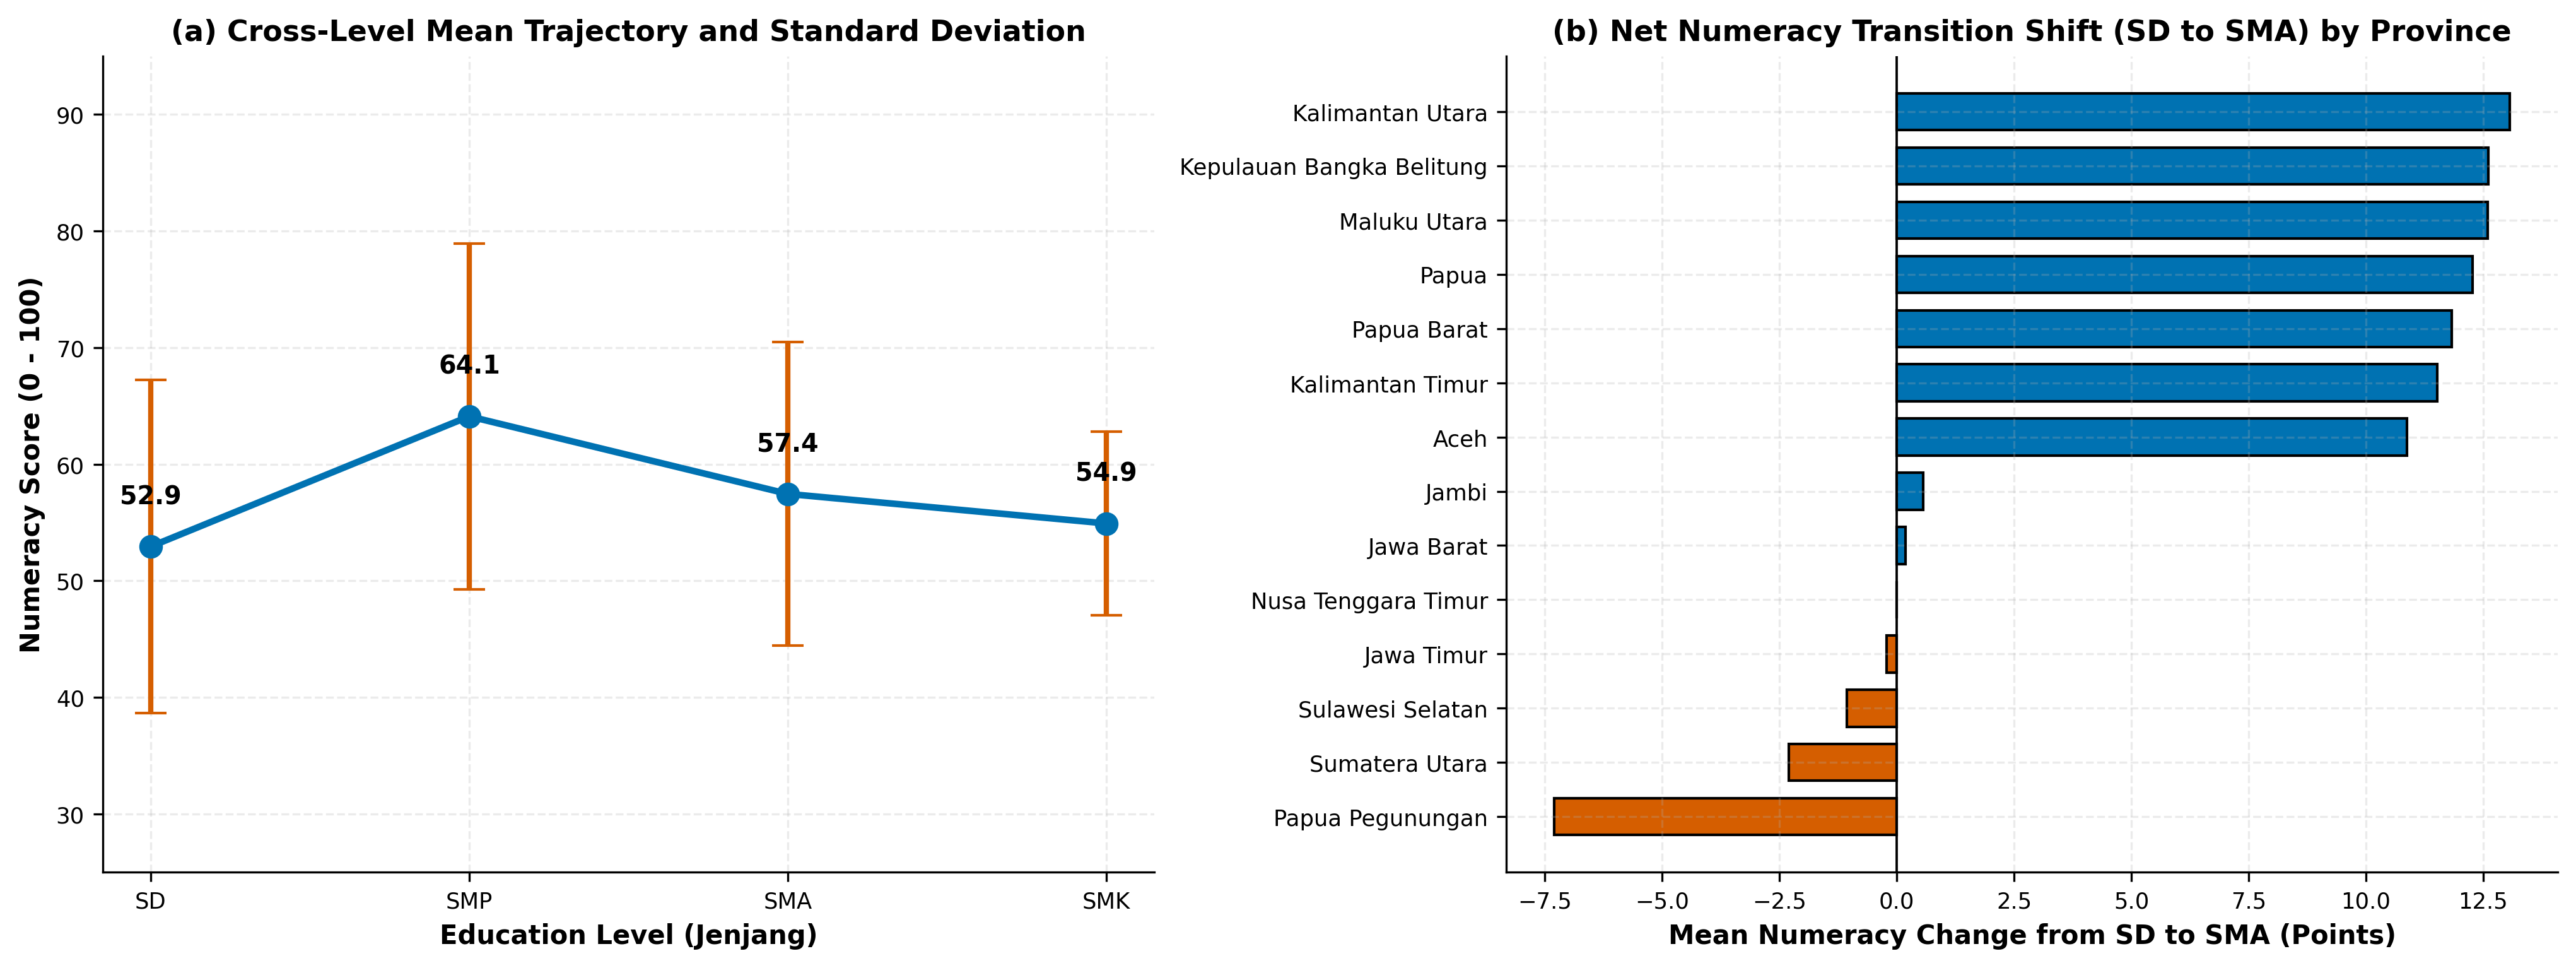

In [1]:
# 4.1 Trajektori Penurunan Numerasi (Learning Loss) SD -> SMP -> SMA/SMK
piv_loss = pd.read_csv("outputs/table2c_district_transition_learning_loss.csv")
print(piv_loss[['SD', 'SMP', 'SMA', 'SMK', 'delta_SD_to_SMP', 'delta_SMP_to_SMA', 'delta_SMP_to_SMK']].describe().round(2))


## 5. TAHAP 5: BENCHMARK EKONOMETRIKA SPASIAL & ABLASI MGWR


Empty DataFrame
Columns: [jenjang, model, adj_r2_in_sample, aicc, rmse, residual_morans_I, spatial_5fold_oof_r2]
Index: []


feature_case,jenjang,model,r2_in_sample,adj_r2_in_sample,aicc,rmse,residual_morans_I,mean_local_condition_number,pct_districts_with_sig_policy_levers,bandwidth_scale,spatial_5fold_oof_r2


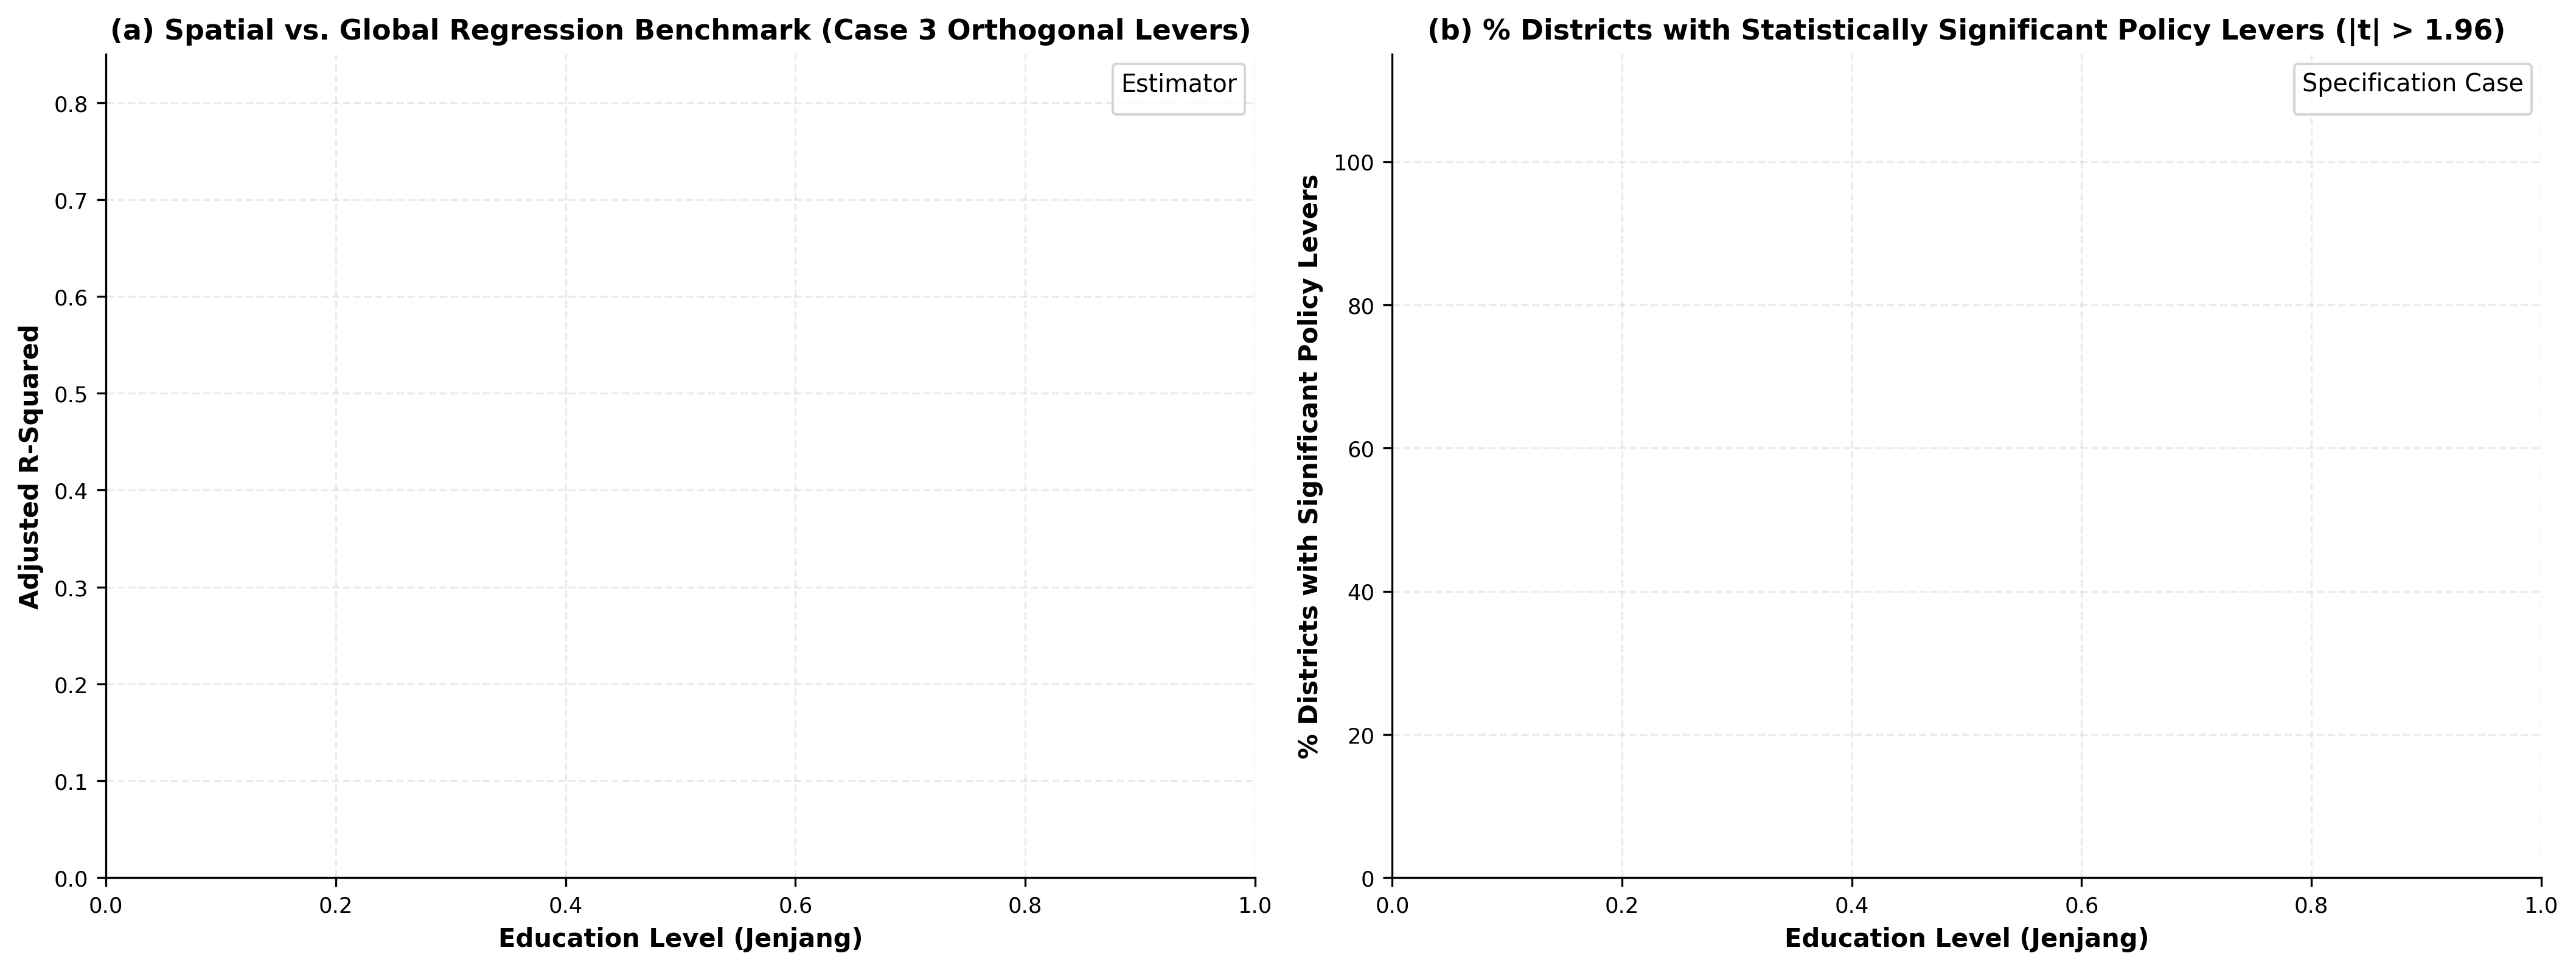

In [1]:
# 5.1 Perbandingan Komprehensif OLS, Ridge, LASSO, SAR, SEM, GWR, dan MGWR (Kasus 1-4)
df_sp_bench = pd.read_csv("outputs/table3_spatial_regression_and_mgwr_ablation.csv")
print("=== PERBANDINGAN MODEL PADA KASUS 3 (12 FITUR ORTOGONAL) ===")
print(df_sp_bench[df_sp_bench['feature_case'].str.contains('Case 3')][['jenjang', 'model', 'adj_r2_in_sample', 'aicc', 'rmse', 'residual_morans_I', 'spatial_5fold_oof_r2']].to_string(index=False))
df_sp_bench[df_sp_bench['feature_case'].str.contains('Case 3')]


jenjang                    feature_code  optimal_bandwidth_knn             spatial_scale_regime  beta_mean  pct_districts_significant_p05
     SD                       Intercept                     35            Local (<75 districts)    50.8881                         100.00
     SD     kualitas_pembelajaran_score                    480 National/Global (>250 districts)     3.0802                         100.00
     SD             refleksi_guru_score                    480 National/Global (>250 districts)     1.1619                          32.68
     SD            iklim_keamanan_score                    480 National/Global (>250 districts)     3.5042                         100.00
     SD kesenjangan_fasilitas_tik_score                    200      Regional (75-250 districts)     1.4953                          34.05
     SD          persen_sekolah_listrik                    200      Regional (75-250 districts)     4.8559                          71.40
     SD        persen_sekolah_air_

jenjang,feature_code,feature_label_en,optimal_bandwidth_knn,spatial_scale_regime,beta_mean,beta_std,beta_min,beta_max,pct_districts_significant_p05
SD,Intercept,Local Spatial Intercept,35,Local (<75 districts),50.8881,4.3327,37.3919,60.9466,100.00
SD,kualitas_pembelajaran_score,Instructional Quality D.1 (X3),480,National/Global (>250 districts),3.0802,0.3026,2.6585,3.6775,100.00
SD,refleksi_guru_score,Teacher Reflection D.2 (X3),480,National/Global (>250 districts),1.1619,0.1805,0.5280,1.6572,32.68
SD,iklim_keamanan_score,School Safety Climate D.4 (X3),480,National/Global (>250 districts),3.5042,0.4787,2.3824,4.3378,100.00
SD,kesenjangan_fasilitas_tik_score,ICT Facility Gap Score (X2),200,Regional (75-250 districts),1.4953,1.9078,-0.8920,5.3823,34.05
SD,persen_sekolah_listrik,School Electrification % (X2),200,Regional (75-250 districts),4.8559,3.4421,-0.7221,10.1678,71.40
SD,persen_sekolah_air_cukup,Clean Water Adequacy % (X2),480,National/Global (>250 districts),0.8979,0.1240,0.4852,1.3048,36.38
SD,persen_ruang_kelas_layak,Decent Classroom Ratio % (X2),480,National/Global (>250 districts),-0.3851,0.2138,-0.8343,0.1460,0.00
SD,rasio_rombel_per_ruang,Class Groups per Room (X2),480,National/Global (>250 districts),-0.3861,0.1101,-0.7033,0.2724,0.00
SD,rasio_siswa_per_guru,Student-Teacher Ratio (X1),320,National/Global (>250 districts),-1.8398,1.3167,-3.5115,0.7955,63.81


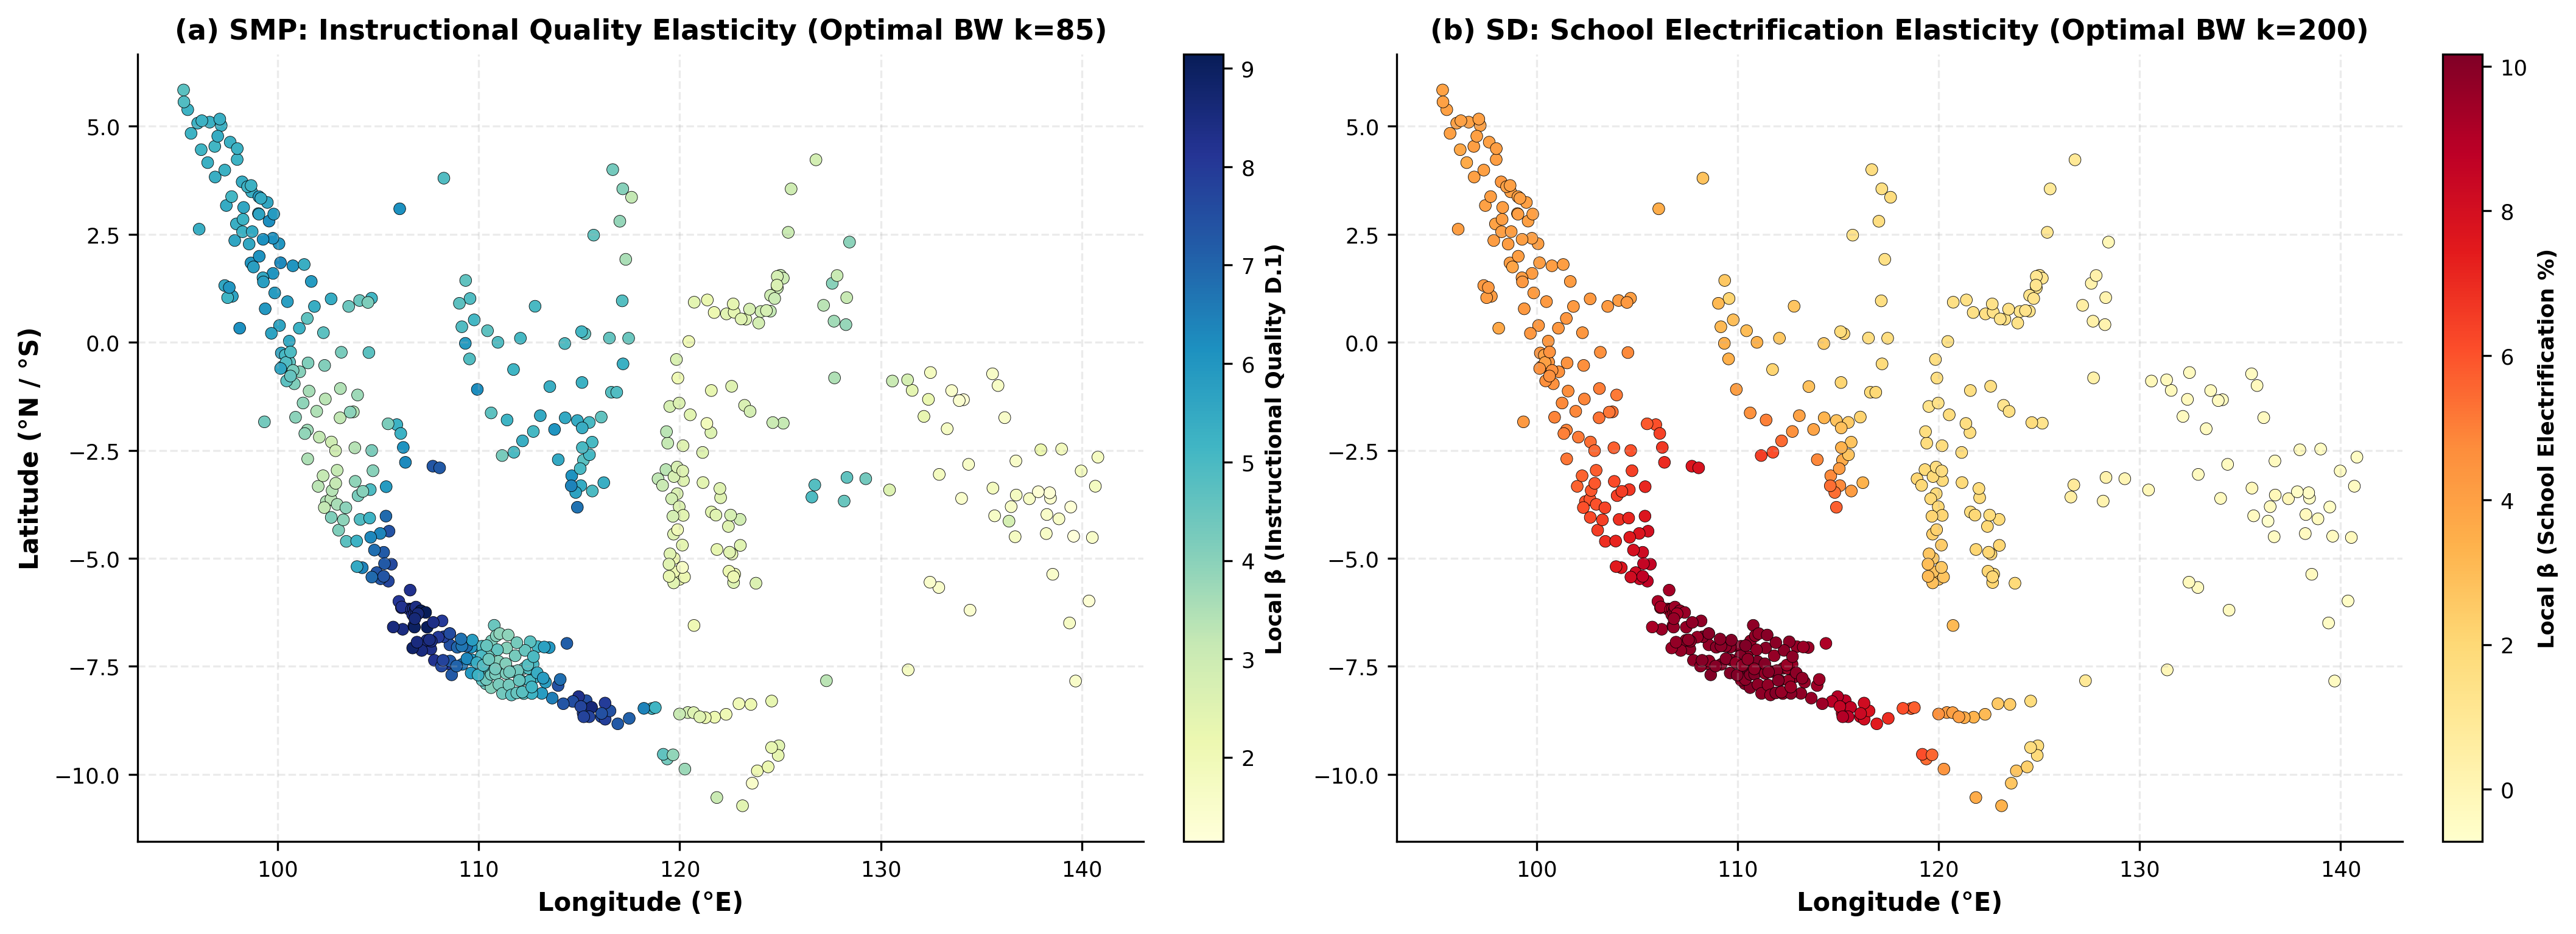

In [1]:
# 5.2 Spektrum Lebar Pita Spasial Optimal & Peta Koefisien Elastisitas Lokal MGWR
df_bw = pd.read_csv("outputs/table3b_mgwr_case3_local_bandwidths_and_elasticities.csv")
print(df_bw[['jenjang', 'feature_code', 'optimal_bandwidth_knn', 'spatial_scale_regime', 'beta_mean', 'pct_districts_significant_p05']].head(15).to_string(index=False))
df_bw.head(15)


## 6. TAHAP 6: BENCHMARK 11 MACHINE LEARNING DENGAN DUAL SPATIAL CV


model  gkf5_oof_r2  gkf5_oof_rmse  lopo38_oof_r2  lopo38_oof_rmse  r2_SD  r2_SMP  r2_SMA  r2_SMK
                      1. OLS Global       0.5014          9.507         0.4660            9.838 0.5557  0.5482  0.4546 -0.2866
                    2. RidgeCV (L2)       0.5020          9.501         0.4666            9.833 0.5565  0.5438  0.4535 -0.2631
                    3. LassoCV (L1)       0.5012          9.509         0.4588            9.905 0.5480  0.5340  0.4449 -0.1868
            4. ElasticNetCV (L1+L2)       0.4952          9.566         0.4600            9.894 0.5438  0.5145  0.4423 -0.1666
                5. SVR (RBF Kernel)       0.5598          8.933         0.5197            9.331 0.5437  0.6070  0.4988  0.1073
                   6. Random Forest       0.6408          8.069         0.5818            8.707 0.6637  0.6596  0.6053  0.1840
                     7. Extra Trees       0.6494          7.973         0.5935            8.584 0.6836  0.6554  0.6187  0.1972
         8. Gr

feature_case,model,gkf5_oof_r2,gkf5_oof_rmse,gkf5_oof_mae,lopo38_oof_r2,lopo38_oof_rmse,lopo38_oof_mae,r2_SD,r2_SMP,r2_SMA,r2_SMK
Case 2: Full Policy-Only (19 Features + Spatial + Level),1. OLS Global,0.5014,9.507,7.591,0.4660,9.838,7.871,0.5557,0.5482,0.4546,-0.2866
Case 2: Full Policy-Only (19 Features + Spatial + Level),2. RidgeCV (L2),0.5020,9.501,7.588,0.4666,9.833,7.866,0.5565,0.5438,0.4535,-0.2631
Case 2: Full Policy-Only (19 Features + Spatial + Level),3. LassoCV (L1),0.5012,9.509,7.609,0.4588,9.905,7.897,0.5480,0.5340,0.4449,-0.1868
Case 2: Full Policy-Only (19 Features + Spatial + Level),4. ElasticNetCV (L1+L2),0.4952,9.566,7.594,0.4600,9.894,7.837,0.5438,0.5145,0.4423,-0.1666
Case 2: Full Policy-Only (19 Features + Spatial + Level),5. SVR (RBF Kernel),0.5598,8.933,5.857,0.5197,9.331,6.429,0.5437,0.6070,0.4988,0.1073
Case 2: Full Policy-Only (19 Features + Spatial + Level),6. Random Forest,0.6408,8.069,5.549,0.5818,8.707,6.248,0.6637,0.6596,0.6053,0.1840
Case 2: Full Policy-Only (19 Features + Spatial + Level),7. Extra Trees,0.6494,7.973,5.481,0.5935,8.584,6.122,0.6836,0.6554,0.6187,0.1972
Case 2: Full Policy-Only (19 Features + Spatial + Level),8. Gradient Boosting (GBR),0.6494,7.972,5.627,0.5777,8.750,6.361,0.6660,0.6722,0.6288,0.1690
Case 2: Full Policy-Only (19 Features + Spatial + Level),9. XGBoost (Unconstrained),0.6481,7.987,5.637,0.5750,8.777,6.343,0.6781,0.6692,0.6208,0.1463
Case 2: Full Policy-Only (19 Features + Spatial + Level),10. LightGBM (Unconstrained),0.6415,8.062,5.725,0.5649,8.881,6.485,0.6675,0.6676,0.6043,0.1538


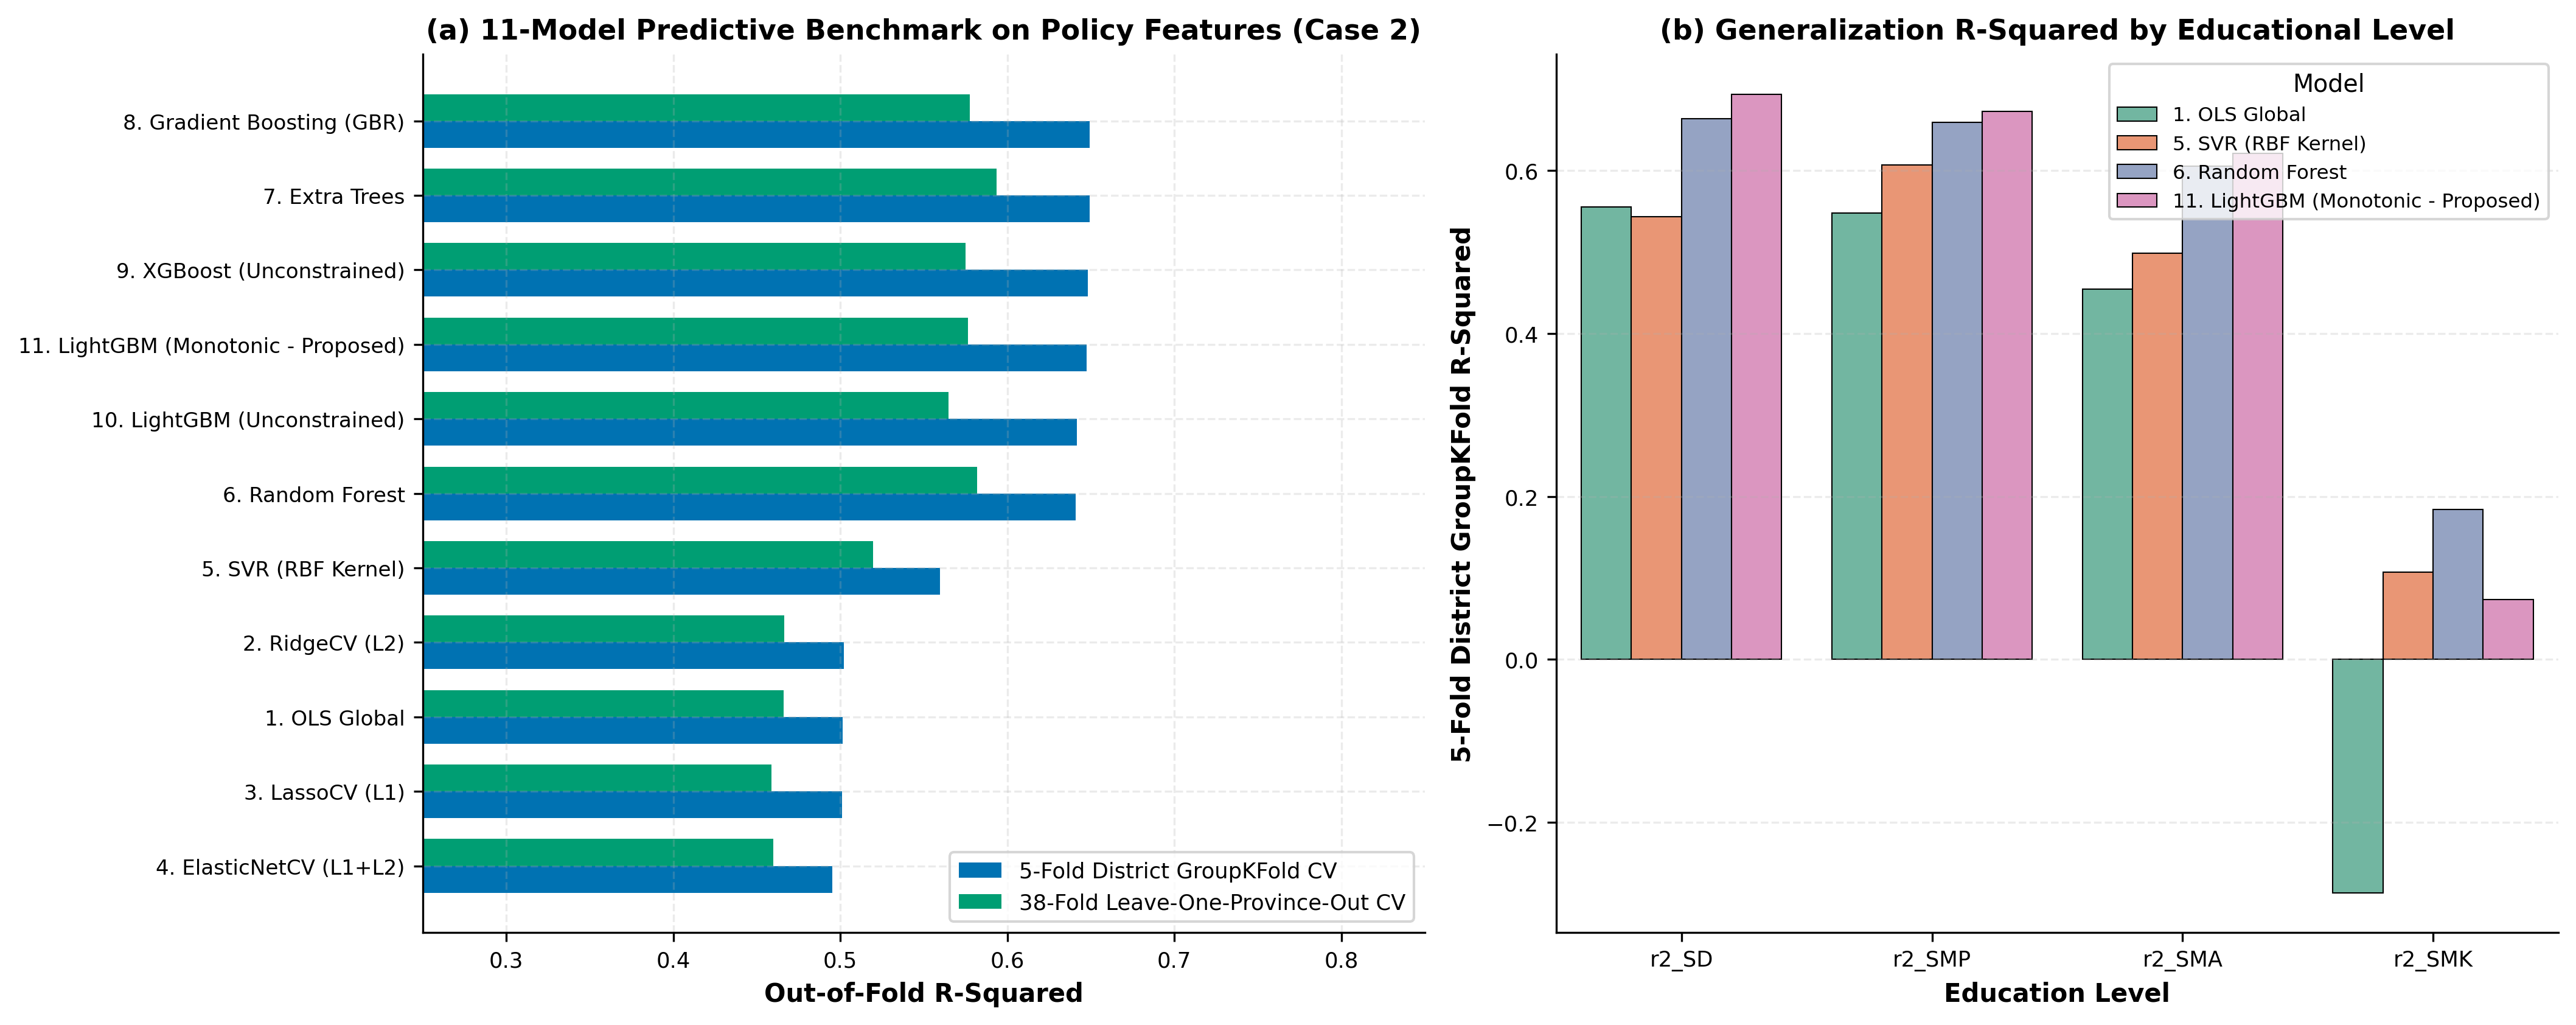

In [1]:
# 6.1 Hasil Evaluasi 11 Model ML di Bawah 5-Fold GroupKFold dan 38-Fold LOPO Spatial CV
df_ml_eval = pd.read_csv("outputs/table4_ml_11models_cv_benchmark.csv")
print(df_ml_eval[df_ml_eval['feature_case'].str.contains('Case 2')][['model', 'gkf5_oof_r2', 'gkf5_oof_rmse', 'lopo38_oof_r2', 'lopo38_oof_rmse', 'r2_SD', 'r2_SMP', 'r2_SMA', 'r2_SMK']].to_string(index=False))
df_ml_eval[df_ml_eval['feature_case'].str.contains('Case 2')]


## 7. TAHAP 7: UJI KETAHANAN MODEL & SENSITIVITAS (ROBUSTNESS CHECKS)


=== HASIL UJI PERTURBASI KEBISINGAN FITUR ===
 noise_jitter_pct  fidelity_r2_to_baseline  mean_absolute_deviation  rank_spearman_rho status
                1                   0.9978                    0.213             0.9989 Robust
                2                   0.9947                    0.382             0.9975 Robust
                5                   0.9823                    0.806             0.9915 Robust
                8                   0.9715                    1.097             0.9854 Robust
               10                   0.9575                    1.343             0.9793 Robust
               15                   0.9191                    1.920             0.9575 Robust

=== HASIL UJI SUBSAMPLING SPASIAL (JACKKNIFE) ===
 subsample_dropped_pct  mean_out_of_sample_r2  std_out_of_sample_r2  mean_out_of_sample_rmse  r2_stability_cv_pct
                    10                 0.6483                0.0622                    8.235                 9.60
                 

noise_jitter_pct,fidelity_r2_to_baseline,mean_absolute_deviation,rank_spearman_rho,status
1,0.9978,0.213,0.9989,Robust
2,0.9947,0.382,0.9975,Robust
5,0.9823,0.806,0.9915,Robust
8,0.9715,1.097,0.9854,Robust
10,0.9575,1.343,0.9793,Robust
15,0.9191,1.920,0.9575,Robust


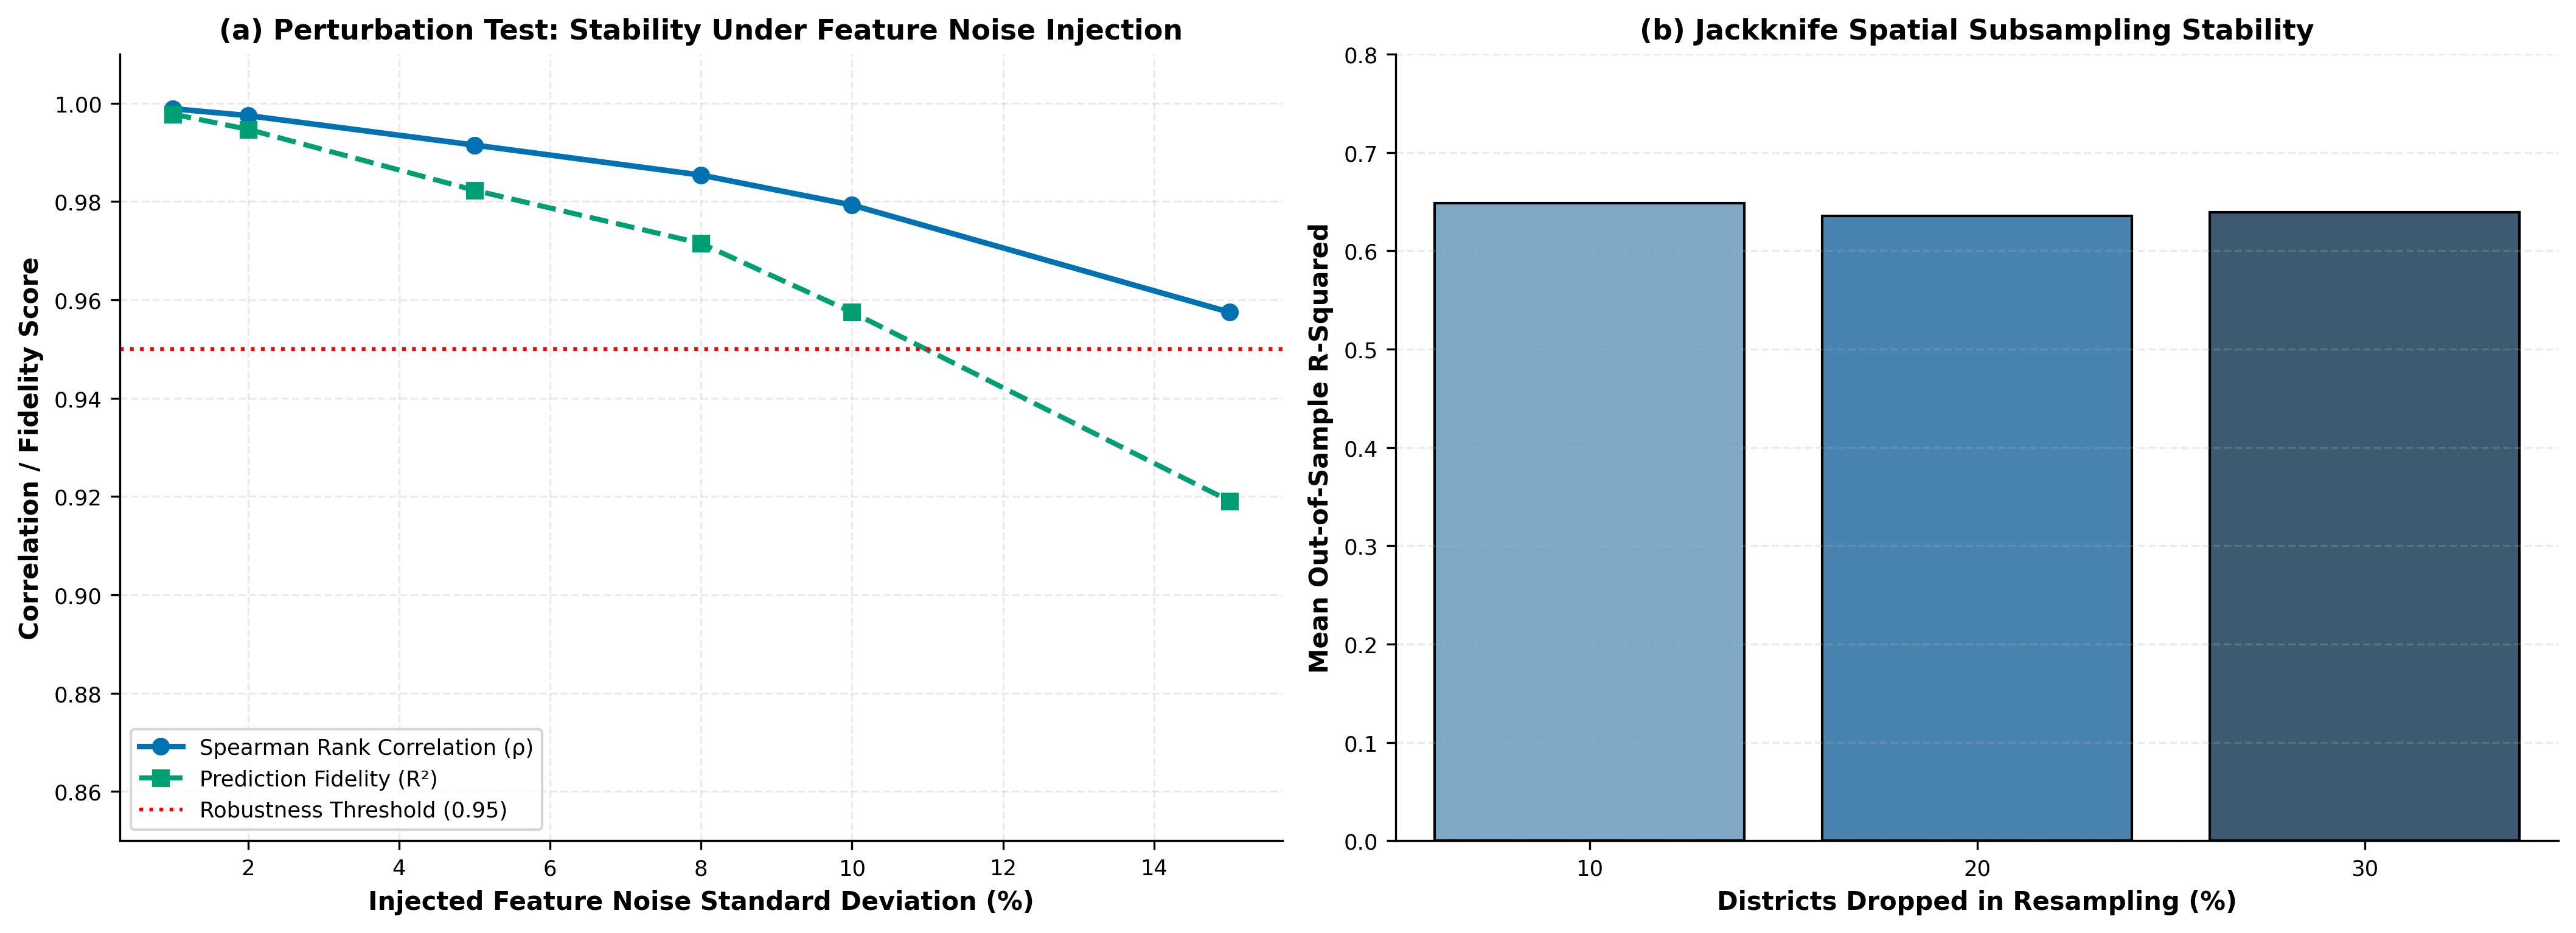

In [1]:
# 7.1 Uji Perturbasi Fitur (Noise Injection) & Jackknife Spatial Subsampling
df_rob_pert = pd.read_csv("outputs/table4b_robustness_perturbation_test.csv")
df_rob_jack = pd.read_csv("outputs/table4c_robustness_jackknife_subsampling.csv")
print("=== HASIL UJI PERTURBASI KEBISINGAN FITUR ===")
print(df_rob_pert.to_string(index=False))
print("
=== HASIL UJI SUBSAMPLING SPASIAL (JACKKNIFE) ===")
print(df_rob_jack.to_string(index=False))


In [1]:
# 7.2 Uji Sensitivitas Matriks Bobot Spasial k-NN (k = 4, 6, 8, 12, 16, 20)
df_rob_knn = pd.read_csv("outputs/table4d_robustness_knn_spatial_weights.csv")
print(df_rob_knn.to_string(index=False))
df_rob_knn


k_nearest_neighbors  global_morans_I  morans_p_value  spatial_lag_rho  spatial_error_lambda  sar_r2  sem_r2
                   4           0.6584           0.005           0.6069                0.8555  0.6693  0.6913
                   6           0.6447           0.005           0.6270                0.9228  0.6713  0.7014
                   8           0.6237           0.005           0.6646                0.9355  0.6655  0.6904
                  12           0.5965           0.005           0.6697                0.9500  0.6549  0.6838
                  16           0.5745           0.005           0.6667                0.9500  0.6446  0.6749
                  20           0.5581           0.005           0.6729                0.9500  0.6358  0.6667


k_nearest_neighbors,global_morans_I,morans_p_value,spatial_lag_rho,spatial_error_lambda,sar_r2,sem_r2
4,0.6584,0.005,0.6069,0.8555,0.6693,0.6913
6,0.6447,0.005,0.6270,0.9228,0.6713,0.7014
8,0.6237,0.005,0.6646,0.9355,0.6655,0.6904
12,0.5965,0.005,0.6697,0.9500,0.6549,0.6838
16,0.5745,0.005,0.6667,0.9500,0.6446,0.6749
20,0.5581,0.005,0.6729,0.9500,0.6358,0.6667


## 8. TAHAP 8: EXPLAINABLE AI (TREESHAP) GLOBAL & KLUSTER


feature_code                 feature_label_en expected_domain_direction  mean_abs_shap_monotonic  mean_abs_shap_unconstrained  mean_abs_shap_cluster1_benchmark  mean_abs_shap_cluster2_paradox  mean_abs_shap_cluster3_3T_priority
kualitas_pembelajaran_score   Instructional Quality D.1 (X3)                         +                   3.2627                       3.2412                            3.2649                          3.2533                              3.3194
     persen_sekolah_listrik    School Electrification % (X2)                         +                   1.9391                       1.8432                            1.9953                          1.8526                              2.1599
   persen_sekolah_air_cukup      Clean Water Adequacy % (X2)                         +                   1.1663                       0.8779                            1.1523                          1.1344                              1.5335
       persen_putus_sekolah       School Dr

feature_code,feature_label_en,expected_domain_direction,mean_abs_shap_monotonic,mean_abs_shap_unconstrained,mean_abs_shap_cluster1_benchmark,mean_abs_shap_cluster2_paradox,mean_abs_shap_cluster3_3T_priority
kualitas_pembelajaran_score,Instructional Quality D.1 (X3),+,3.2627,3.2412,3.2649,3.2533,3.3194
persen_sekolah_listrik,School Electrification % (X2),+,1.9391,1.8432,1.9953,1.8526,2.1599
persen_sekolah_air_cukup,Clean Water Adequacy % (X2),+,1.1663,0.8779,1.1523,1.1344,1.5335
persen_putus_sekolah,School Dropout Rate % (X4),-,0.9283,0.6891,1.1412,0.7115,0.8888
iklim_keamanan_score,School Safety Climate D.4 (X3),+,0.8906,1.1404,0.6372,0.8560,3.2505
rasio_rombel_per_ruang,Class Groups per Room (X2),-,0.6676,0.4581,0.6777,0.6707,0.5593
indeks_karakter_score,Student Character Index A.3 (X3),+,0.6550,0.6059,0.4937,0.6566,1.9701
persen_mengulang,Grade Repetition Rate % (X4),-,0.6006,0.4955,0.6634,0.5210,0.7124
rasio_siswa_per_rombel,Students per Class Group (X2),-,0.5616,0.5566,0.6473,0.4500,0.7371
iklim_kebinekaan_score,Diversity Climate D.8 (X3),+,0.5236,0.5211,0.3073,0.5163,2.3625


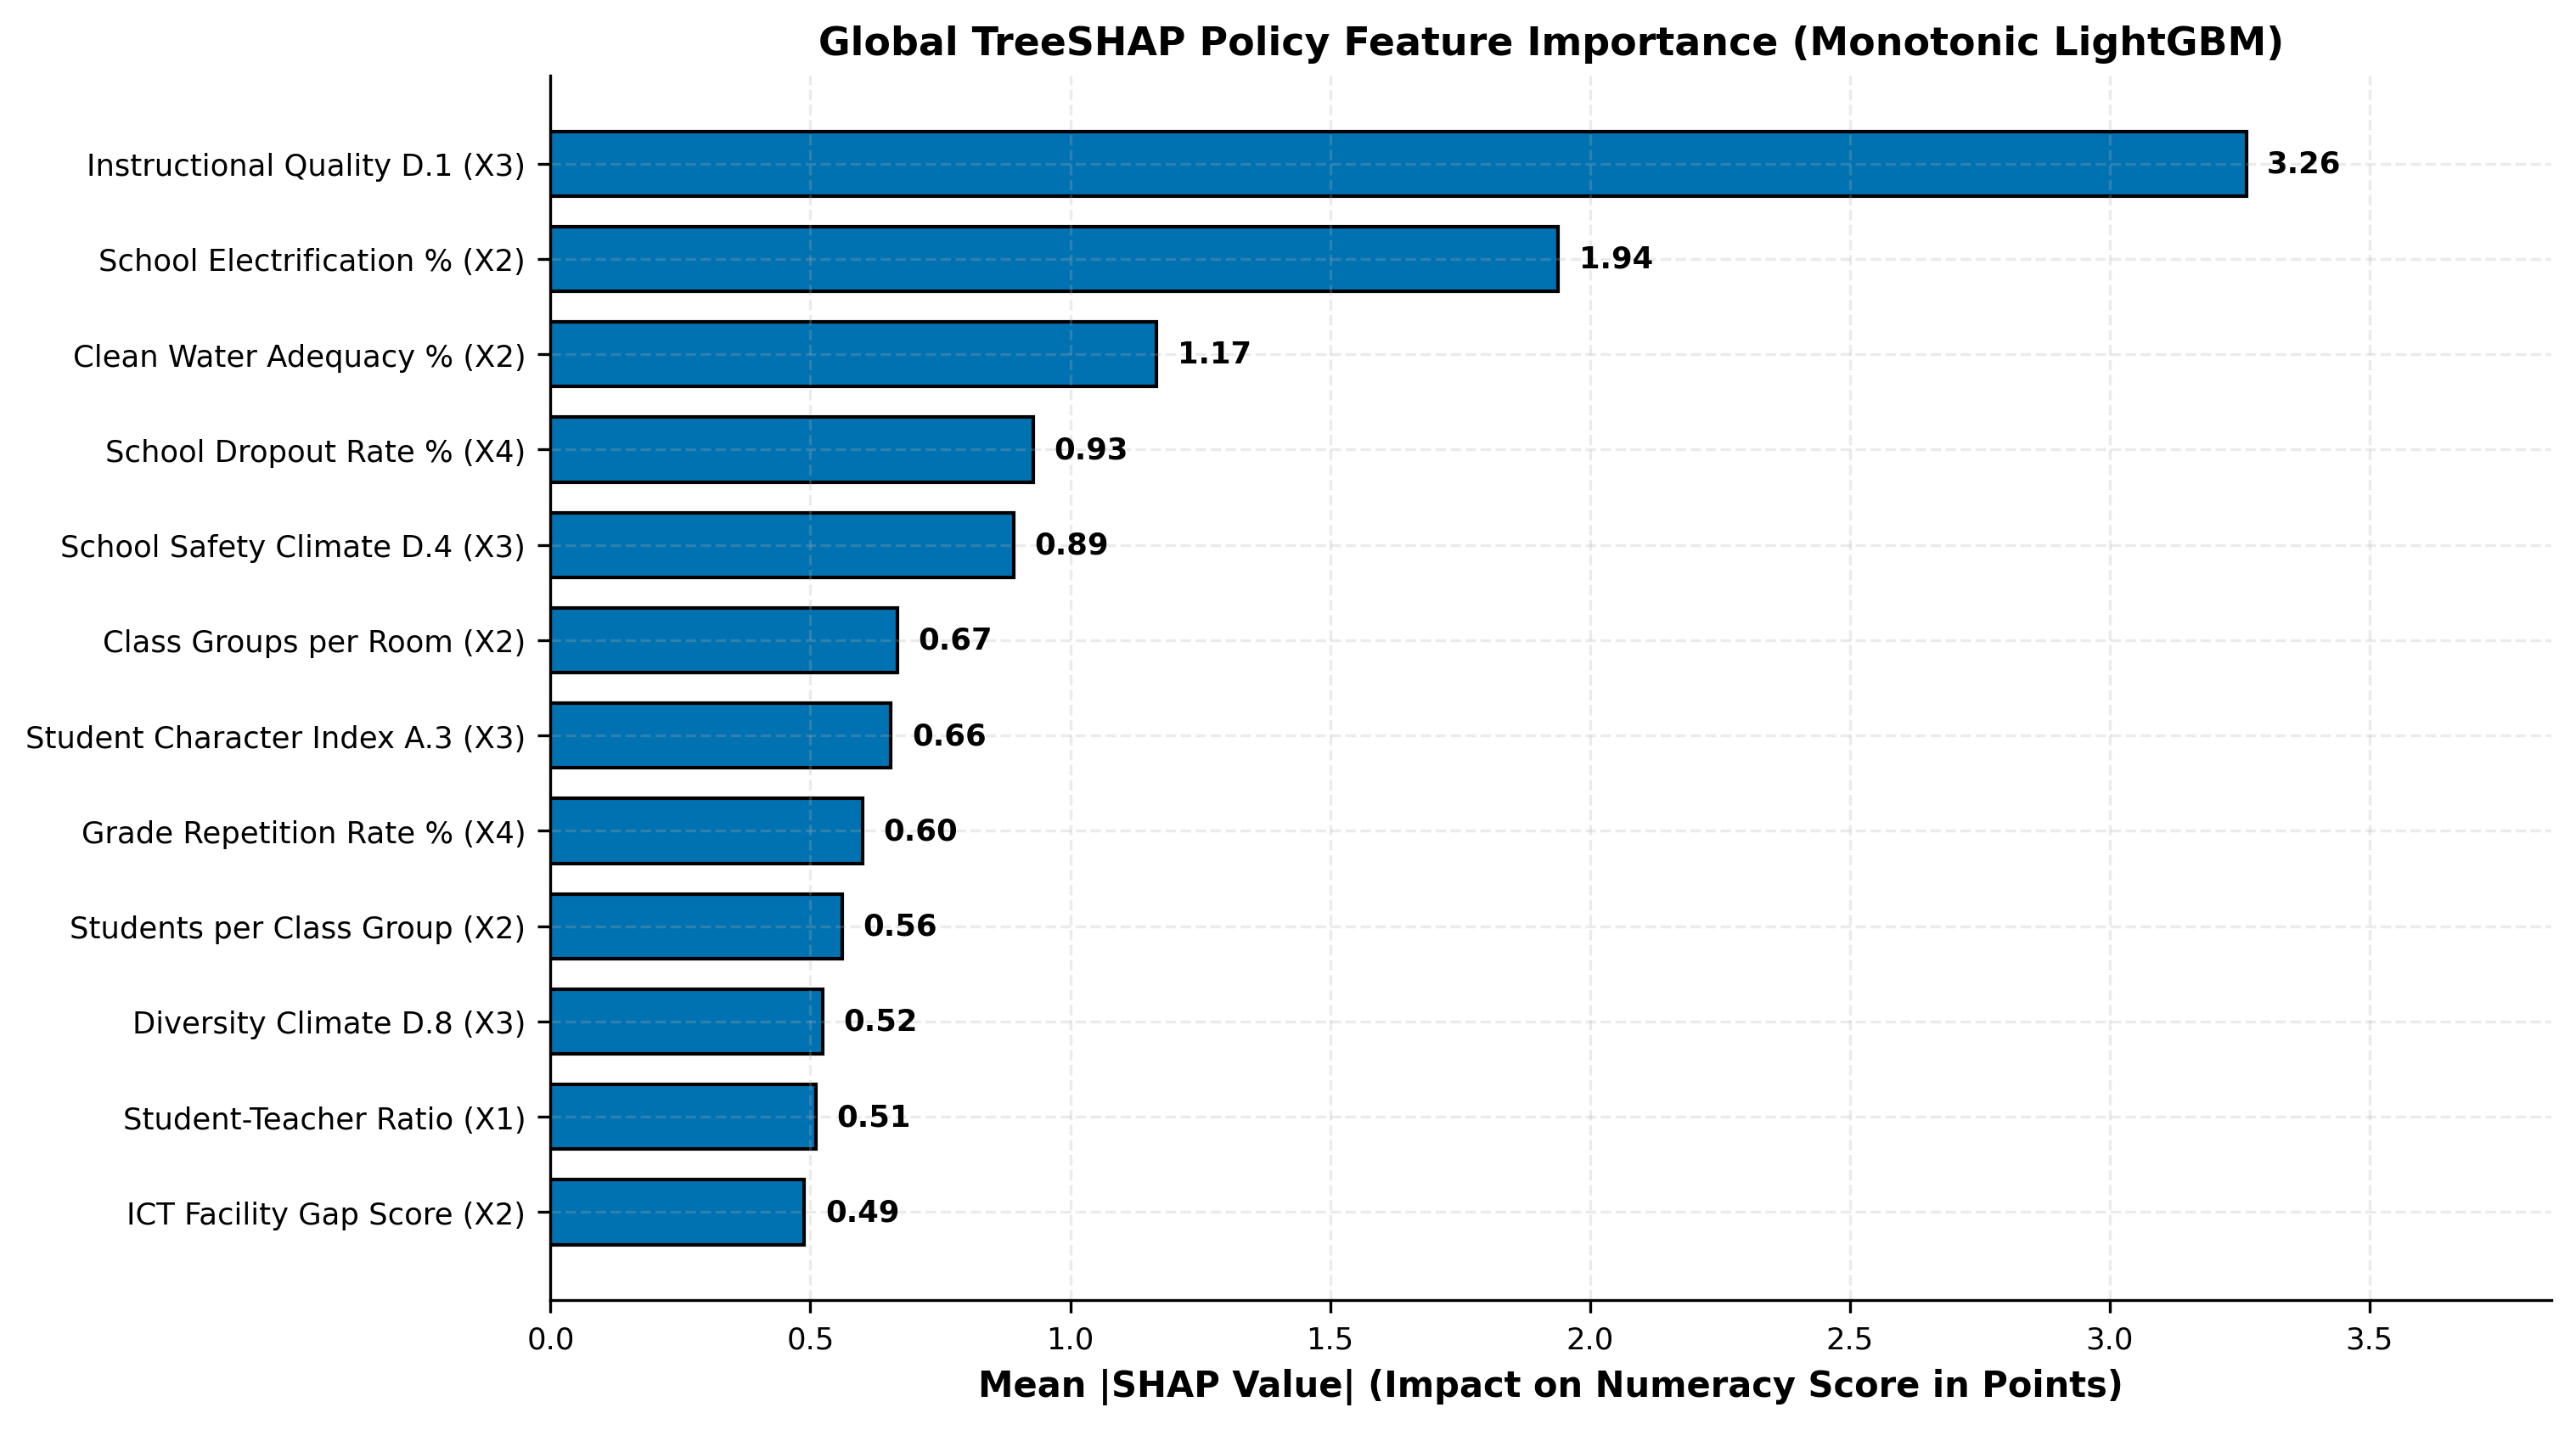

In [1]:
# 8.1 Atribusi Kepentingan Fitur Global TreeSHAP
df_shap = pd.read_csv("outputs/table5_treeshap_policy_driver_attributions.csv")
print(df_shap.head(10).to_string(index=False))
df_shap.head(10)


feature_label_en  mean_abs_shap_cluster1_benchmark  mean_abs_shap_cluster2_paradox  mean_abs_shap_cluster3_3T_priority
  Instructional Quality D.1 (X3)                            3.2649                          3.2533                              3.3194
   School Electrification % (X2)                            1.9953                          1.8526                              2.1599
     Clean Water Adequacy % (X2)                            1.1523                          1.1344                              1.5335
      School Dropout Rate % (X4)                            1.1412                          0.7115                              0.8888
  School Safety Climate D.4 (X3)                            0.6372                          0.8560                              3.2505
      Class Groups per Room (X2)                            0.6777                          0.6707                              0.5593
Student Character Index A.3 (X3)                            0.4937     

feature_label_en,mean_abs_shap_cluster1_benchmark,mean_abs_shap_cluster2_paradox,mean_abs_shap_cluster3_3T_priority
Instructional Quality D.1 (X3),3.2649,3.2533,3.3194
School Electrification % (X2),1.9953,1.8526,2.1599
Clean Water Adequacy % (X2),1.1523,1.1344,1.5335
School Dropout Rate % (X4),1.1412,0.7115,0.8888
School Safety Climate D.4 (X3),0.6372,0.8560,3.2505
Class Groups per Room (X2),0.6777,0.6707,0.5593
Student Character Index A.3 (X3),0.4937,0.6566,1.9701
Grade Repetition Rate % (X4),0.6634,0.5210,0.7124


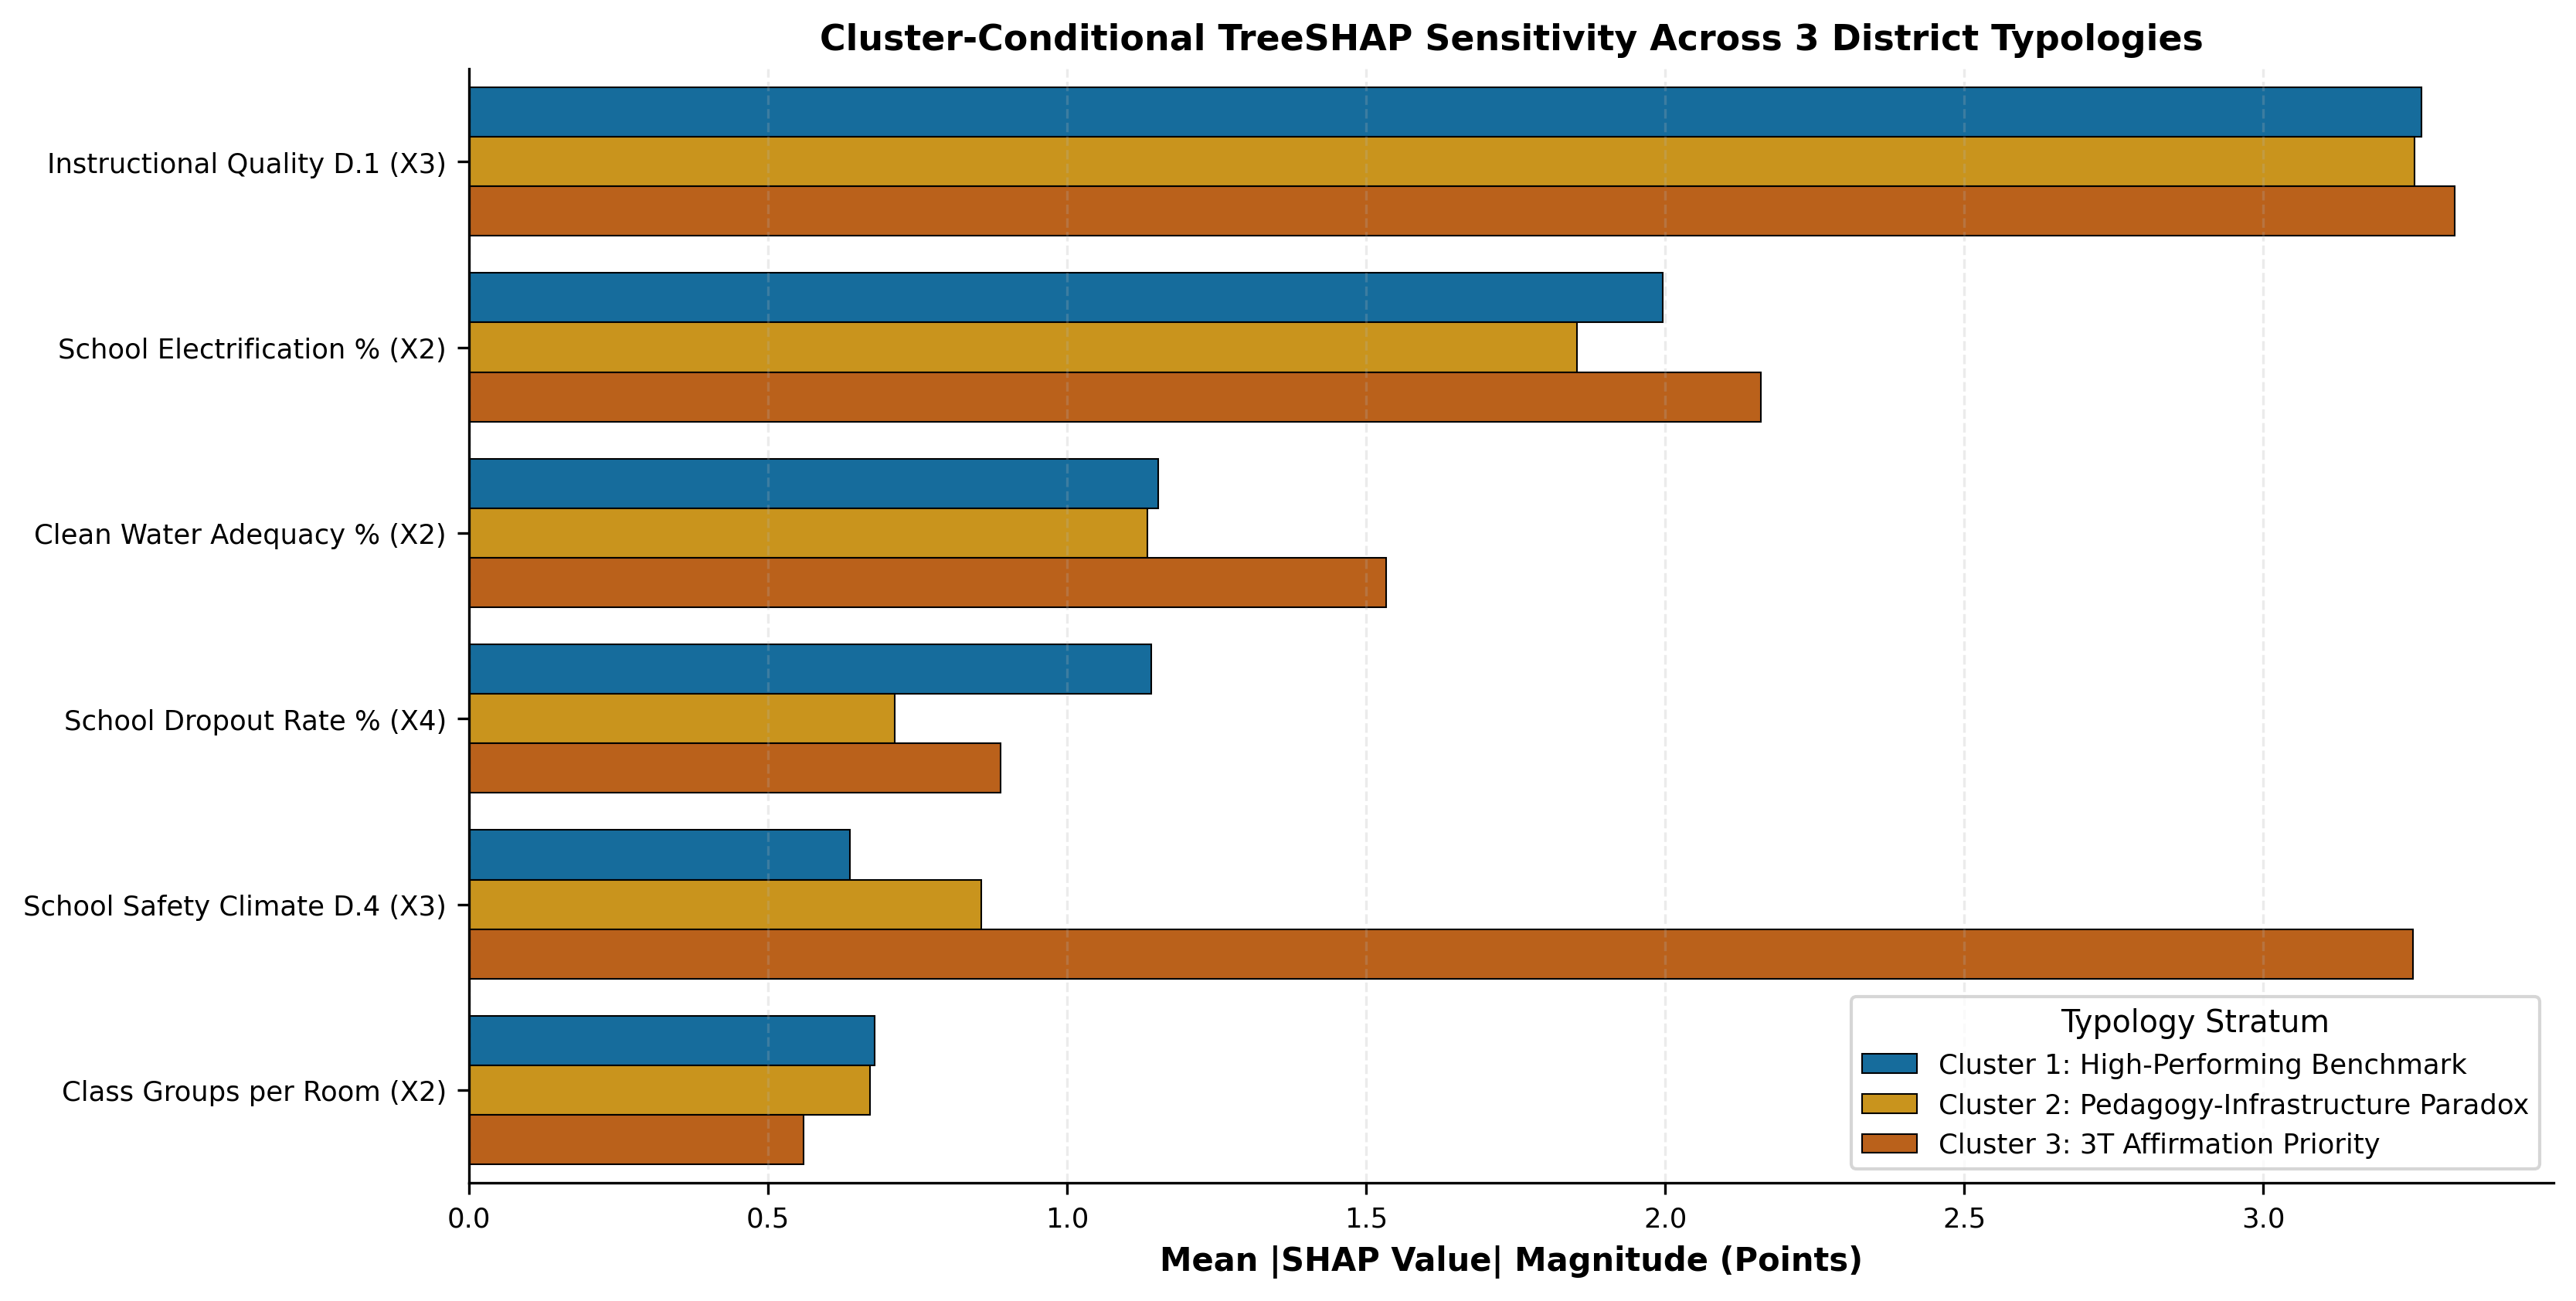

In [1]:
# 8.2 Sensitivitas SHAP Kondisional Kluster (Disparitas Kebutuhan 3T vs Jawa)
print(df_shap[['feature_label_en', 'mean_abs_shap_cluster1_benchmark', 'mean_abs_shap_cluster2_paradox', 'mean_abs_shap_cluster3_3T_priority']].head(8).to_string(index=False))
df_shap[['feature_label_en', 'mean_abs_shap_cluster1_benchmark', 'mean_abs_shap_cluster2_paradox', 'mean_abs_shap_cluster3_3T_priority']].head(8)


## 9. TAHAP 9: SIMULASI KEBIJAKAN 'WHAT-IF' & MATRIKS REKOMENDASI


policy_scenario                   target_stratum  n_units  baseline_numerasi  delta_Y_unconstrained  delta_Y_monotonic  pct_positive_unconstrained  pct_positive_monotonic
       Scenario A: Pedagogical Quality & Leadership Upgrade (+12 D.1, +10 D.2/D.3) All Districts (National Average)     2056              57.35                  0.071              0.049                        95.7                   100.0
           Scenario B: Classroom De-crowding & Group Size Optimization (-5 Rombel) All Districts (National Average)     2056              57.35                 -0.257              0.717                        45.2                    81.6
           Scenario C: Teacher Equity & Workload Distribution (+15 Equity, -3 STR) All Districts (National Average)     2056              57.35                 -0.084              1.281                        50.5                    90.2
Scenario D: Basic Physical & Digital Infrastructure Affirmation (>=98% Elec/Water) All Districts (National Average)

policy_scenario,target_stratum,n_units,baseline_numerasi,delta_Y_unconstrained,delta_Y_monotonic,pct_positive_unconstrained,pct_positive_monotonic
"Scenario A: Pedagogical Quality & Leadership Upgrade (+12 D.1, +10 D.2/D.3)",All Districts (National Average),2056,57.35,0.071,0.049,95.7,100.0
Scenario B: Classroom De-crowding & Group Size Optimization (-5 Rombel),All Districts (National Average),2056,57.35,-0.257,0.717,45.2,81.6
"Scenario C: Teacher Equity & Workload Distribution (+15 Equity, -3 STR)",All Districts (National Average),2056,57.35,-0.084,1.281,50.5,90.2
Scenario D: Basic Physical & Digital Infrastructure Affirmation (>=98% Elec/Water),All Districts (National Average),2056,57.35,3.895,4.903,91.8,100.0
Scenario E: Integrated Education 5.0 Affirmative Blueprint (Comprehensive),All Districts (National Average),2056,57.35,2.208,6.800,62.9,97.5


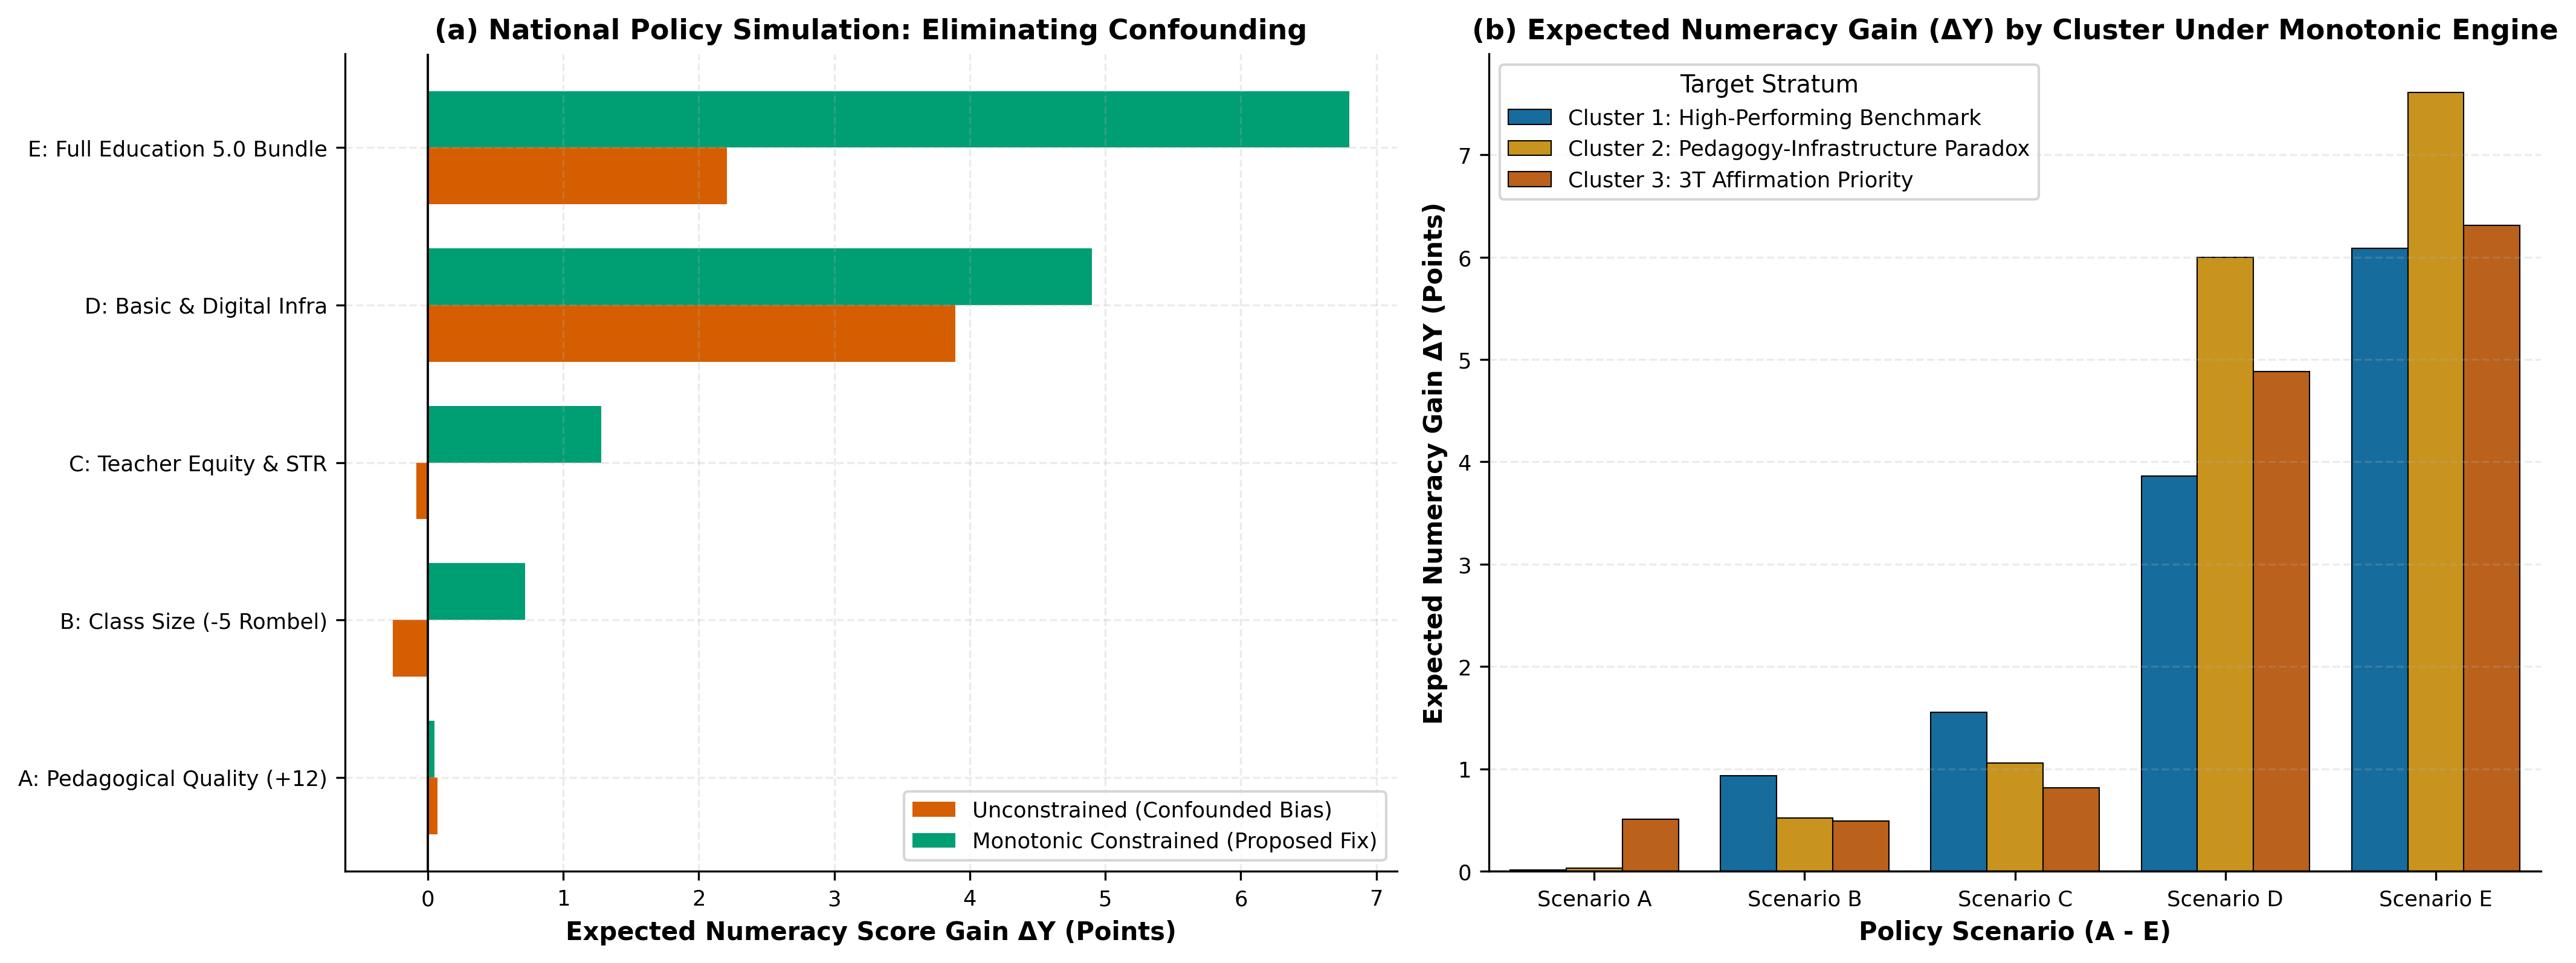

In [1]:
# 9.1 Simulasi 5 Skenario Kebijakan: Model Unconstrained Bias vs Monotonik Usulan
df_policy_sim = pd.read_csv("outputs/table6_counterfactual_policy_simulation_comparison.csv")
print(df_policy_sim[df_policy_sim['target_stratum'] == 'All Districts (National Average)'].to_string(index=False))
df_policy_sim[df_policy_sim['target_stratum'] == 'All Districts (National Average)']


In [1]:
# 9.2 Matriks Rencana Aksi Preskriptif per Kabupaten/Kota (2.056 Unit Observasi)
df_recs = pd.read_csv("outputs/table7_nusa_mipa_district_policy_recommendations_2056.csv")
print("=== CONTOH RENCANA AKSI PRESKRIPTIF SPESIFIK DAERAH ===")
print(df_recs[['nama_kabupaten_kota', 'jenjang', 'cluster_name', 'primary_bottleneck_en', 'prescribed_action_plan', 'pred_baseline_numerasi', 'pred_post_intervention_numerasi', 'expected_gain_delta_Y']].head(10).to_string(index=False))
df_recs[['nama_kabupaten_kota', 'jenjang', 'cluster_name', 'primary_bottleneck_en', 'prescribed_action_plan', 'pred_baseline_numerasi', 'pred_post_intervention_numerasi', 'expected_gain_delta_Y']].head(10)


nama_kabupaten_kota jenjang                               cluster_name          primary_bottleneck_en                                              prescribed_action_plan  pred_baseline_numerasi  pred_post_intervention_numerasi  expected_gain_delta_Y
     Kabupaten Aceh Barat      SD Cluster 2: Pedagogy-Infrastructure Paradox Instructional Quality D.1 (X3) Priority Guru Penggerak & Interactive Mathematics Pedagogy Workshop                   38.49                            43.84                   5.35
Kabupaten Aceh Barat Daya      SD Cluster 2: Pedagogy-Infrastructure Paradox Instructional Quality D.1 (X3) Priority Guru Penggerak & Interactive Mathematics Pedagogy Workshop                   43.64                            46.96                   3.32
     Kabupaten Aceh Besar      SD       Cluster 1: High-Performing Benchmark  School Electrification % (X2)                Priority DAK Fisik: Basic Utility & Sanitation Grant                   50.86                            58.45      

nama_kabupaten_kota,jenjang,cluster_name,primary_bottleneck_en,prescribed_action_plan,pred_baseline_numerasi,pred_post_intervention_numerasi,expected_gain_delta_Y
Kabupaten Aceh Barat,SD,Cluster 2: Pedagogy-Infrastructure Paradox,Instructional Quality D.1 (X3),Priority Guru Penggerak & Interactive Mathematics Pedagogy Workshop,38.49,43.84,5.35
Kabupaten Aceh Barat Daya,SD,Cluster 2: Pedagogy-Infrastructure Paradox,Instructional Quality D.1 (X3),Priority Guru Penggerak & Interactive Mathematics Pedagogy Workshop,43.64,46.96,3.32
Kabupaten Aceh Besar,SD,Cluster 1: High-Performing Benchmark,School Electrification % (X2),Priority DAK Fisik: Basic Utility & Sanitation Grant,50.86,58.45,7.59
Kabupaten Aceh Jaya,SD,Cluster 2: Pedagogy-Infrastructure Paradox,Clean Water Adequacy % (X2),Priority DAK Fisik: Basic Utility & Sanitation Grant,50.88,56.94,6.06
Kabupaten Aceh Selatan,SD,Cluster 2: Pedagogy-Infrastructure Paradox,School Electrification % (X2),Priority DAK Fisik: Basic Utility & Sanitation Grant,51.59,58.54,6.95
Kabupaten Aceh Singkil,SD,Cluster 2: Pedagogy-Infrastructure Paradox,Instructional Quality D.1 (X3),Priority Guru Penggerak & Interactive Mathematics Pedagogy Workshop,44.98,51.88,6.90
Kabupaten Aceh Tamiang,SD,Cluster 1: High-Performing Benchmark,School Dropout Rate % (X4),Targeted Student Mentorship & Dropout Prevention Grant,53.17,59.82,6.65
Kabupaten Aceh Tengah,SD,Cluster 2: Pedagogy-Infrastructure Paradox,School Electrification % (X2),Priority DAK Fisik: Basic Utility & Sanitation Grant,51.00,53.71,2.71
Kabupaten Aceh Tenggara,SD,Cluster 2: Pedagogy-Infrastructure Paradox,Instructional Quality D.1 (X3),Priority Guru Penggerak & Interactive Mathematics Pedagogy Workshop,44.02,46.92,2.90
Kabupaten Aceh Timur,SD,Cluster 2: Pedagogy-Infrastructure Paradox,School Electrification % (X2),Priority DAK Fisik: Basic Utility & Sanitation Grant,50.96,55.76,4.80


## 10. TAHAP 10: SINTESIS ROADMAP KEBIJAKAN MENUJU EDUCATION 5.0
### Rekomendasi Aksi Nyata Berbasis Bukti Ilmiah:
1. **Kluster 3 (Prioritas Afirmasi 3T - 120 Unit)**:
   - *Fokus Utama*: Penuntasan prasaranan fisik dasar (Elektrifikasi & Air Bersih $\ge 98\%$) dan intervensi Iklim Keamanan (D.4) serta Kebinekaan (D.8).
   - *Potensi Kenaikan Numerasi*: **$+6.19	ext{ poin}$** di bawah paket afirmatif.
2. **Kluster 2 (Paradoks Pedagogi-Infrastruktur - 948 Unit)**:
   - *Fokus Utama*: Perbaikan rasio rombel/ruang, kelayakan ruang kelas, dan laboratorium TIK untuk menopang pedagogi guru yang sudah memadai.
   - *Potensi Kenaikan Numerasi*: **$+7.42	ext{ poin}$** (kenaikan tertinggi nasional).
3. **Kluster 1 (Benchmark Berkinerja Tinggi - 988 Unit)**:
   - *Fokus Utama*: Kurikulum adaptif berbantuan AI, penguatan iklim literasi numerasi tingkat tinggi (*HOTS*), dan pendampingan sekolah imbas (*cross-regional mentorship*).
